# Telco churn: who should get a retention offer?

Churn model on the IBM Telco sample (7,043 customers), with the decision threshold chosen by the expected
value of an offer instead of a default 0.5.

**Contents**

1. Clean, split and explore (training split only)
2. Tune and compare models
3. Choose the model and threshold by expected value; sensitivity; per-customer value
4. Final test evaluation (the only place the test split is read) and fairness check
5. SHAP explanations and error analysis
6. Survival analysis
7. Model card

Run top to bottom from the project folder, with the raw CSV in `data/`. Every step is seeded. The what-if app
(`streamlit run app.py`) uses the model and threshold saved here.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import json
import joblib
import numpy as np
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    brier_score_loss,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import itertools
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
import warnings
import shap
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test, proportional_hazard_test

import copy
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, brier_score_loss, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Everything generated goes under data/: splits, models (data/models) and result files (data/results).
ROOT = Path(".")
PROCESSED = Path("data")
DOCS = IMG = PROCESSED / "results"
MODELS_DIR = PROCESSED / "models"
for d in (DOCS, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)


def show(markdown: str) -> None:
    """Render a generated report as markdown in the notebook."""
    display(Markdown(markdown))

## Settings, data loading and splitting

All tunable settings and the business **assumptions** are in `CONFIG`. The split happens on cleaned-but-unencoded data; scaling and encoding happen later inside a scikit-learn Pipeline fit on the training set only.

In [2]:
TARGET = "Churn"


ID_COL = "customerID"


NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]


CATEGORICAL = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
]


FEATURES = NUMERIC + CATEGORICAL


# All tunable settings and business ASSUMPTIONS live here.
CONFIG: dict = {
    "seed": 42,
    "data": {
        "raw_file": "data/WA_Fn-UseC_-Telco-Customer-Churn.csv",
        # Stratified split: 60% train, 20% validation, 20% test.
        "val_size": 0.20,
        "test_size": 0.20,
    },
    "cv": {
        "folds": 5,
        "scoring": "average_precision",  # PR-AUC: suits a 27% positive class
    },
    # Business ASSUMPTIONS for the expected-value threshold. These are NOT from the data:
    # illustrative numbers chosen to be plausible for a consumer telecom. The
    # sensitivity analysis in Part 3 shows how the chosen threshold moves when they change.
    #   offer_cost:         cost of one retention offer (discount plus agent time), paid for
    #                       EVERY customer we target, churner or not.
    #   customer_value:     value lost when a customer churns; ~15 months of the average
    #                       monthly bill (~$65/month in this data).
    #   offer_success_rate: share of would-be churners who stay because of the offer.
    # Expected value of targeting one customer with churn probability p:
    #   EV = p * offer_success_rate * customer_value - offer_cost
    "economics": {"offer_cost": 100, "customer_value": 1000, "offer_success_rate": 0.40},
    # Per-customer value (Part 3 below): a lost customer is worth their own
    # MonthlyCharges x value_months. 15 months keeps the average close to the flat $1,000
    # above, so the two setups are comparable. Still an ASSUMPTION: it ignores margins and
    # how long each customer would stay.
    "per_customer_value": {"value_months": 15, "value_months_grid": [6, 15, 30]},
    # Grid for the sensitivity analysis (each varied around the base case).
    "sensitivity": {
        "offer_cost": [50, 100, 200],
        "customer_value": [500, 1000, 2000],
        "offer_success_rate": [0.2, 0.4, 0.6],
    },
}


def load_config() -> dict:
    """The settings above (a copy, so callers can't change them by accident)."""
    return copy.deepcopy(CONFIG)


def load_raw(cfg: dict | None = None) -> pd.DataFrame:
    """Read the raw CSV exactly as downloaded."""
    cfg = cfg or load_config()
    return pd.read_csv(ROOT / cfg["data"]["raw_file"])


def clean(df: pd.DataFrame) -> pd.DataFrame:
    """Fix data types. Row-wise rules only, so it is safe to run before splitting.

    - TotalCharges is text because 11 rows hold a single space. All 11 have
      tenure 0 (new customers not yet billed), so their true total is 0.
    - SeniorCitizen is stored 0/1 while every other yes/no column is text;
      convert to "Yes"/"No" so it is one-hot encoded like the rest.
    - Churn becomes 1/0.
    """
    df = df.copy()
    tc = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")
    blank = tc.isna()
    assert (df.loc[blank, "tenure"] == 0).all(), "blank TotalCharges expected only for tenure 0"
    df["TotalCharges"] = tc.fillna(0.0)
    df["SeniorCitizen"] = df["SeniorCitizen"].map({1: "Yes", 0: "No"})
    df[TARGET] = (df[TARGET] == "Yes").astype(int)
    return df


def split(df: pd.DataFrame, cfg: dict | None = None) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Stratified train / validation / test split with a fixed seed."""
    cfg = cfg or load_config()
    seed, test_size, val_size = cfg["seed"], cfg["data"]["test_size"], cfg["data"]["val_size"]
    train_val, test = train_test_split(df, test_size=test_size, stratify=df[TARGET], random_state=seed)
    # val_size is a share of the full data, so rescale it for the remaining rows.
    train, val = train_test_split(
        train_val, test_size=val_size / (1 - test_size), stratify=train_val[TARGET], random_state=seed
    )
    return train, val, test


def xy(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Separate features from the target."""
    return df[FEATURES], df[TARGET]


def load_split(name: str) -> pd.DataFrame:
    """Read a saved split, keeping types consistent with clean()."""
    df = pd.read_csv(PROCESSED / f"{name}.csv")
    return df

## Model pipelines

Every model is a `Pipeline(preprocess -> classifier)`, so when it is fit on the training set the scaler and encoder only ever see training rows. Cross-validation on a Pipeline refits the preprocessing inside each fold too.

In [3]:
def build_preprocessor() -> ColumnTransformer:
    """Scale numeric columns, one-hot encode categoricals."""
    return ColumnTransformer(
        [
            ("num", StandardScaler(), NUMERIC),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
        ],
        verbose_feature_names_out=False,
    )


def make_pipeline(name: str, seed: int) -> Pipeline:
    """Return an unfitted pipeline for one of the supported model names."""
    models = {
        "logreg_unweighted": LogisticRegression(max_iter=2000),
        "logreg": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "random_forest": RandomForestClassifier(
            n_estimators=400, class_weight="balanced", random_state=seed, n_jobs=-1
        ),
        "gradient_boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=seed),
    }
    return Pipeline([("prep", build_preprocessor()), ("model", models[name])])


# Search spaces for cross-validated tuning on the training set.
PARAM_GRIDS: dict[str, dict] = {
    "logreg": {"model__C": [0.01, 0.1, 1.0, 10.0]},
    "random_forest": {
        "model__max_depth": [6, 10, None],
        "model__min_samples_leaf": [1, 5, 20],
        "model__max_features": ["sqrt", 0.5],
    },
    "gradient_boosting": {
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [3, 6],
        "model__max_iter": [100, 300],
        "model__l2_regularization": [0.0, 1.0],
    },
}

## Scoring helpers

Classification metrics, the expected value of an offer, per-customer values and SHAP values, used throughout the parts below.

In [4]:
THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.01), 2)


def evaluate(y: np.ndarray, p: np.ndarray, threshold: float = 0.5) -> dict[str, float]:
    """Classification metrics at a threshold plus threshold-free scores."""
    pred = (p >= threshold).astype(int)
    return {
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
        "pr_auc": average_precision_score(y, p),
        "roc_auc": roc_auc_score(y, p),
        "brier": brier_score_loss(y, p),
        "accuracy": accuracy_score(y, pred),
    }


def expected_value(
    y: np.ndarray, p: np.ndarray, threshold: float, offer_cost: float, customer_value: float, success_rate: float
) -> float:
    """Total expected value of targeting everyone with p >= threshold.

    Targeted churner: success_rate * customer_value - offer_cost. Targeted non-churner: -offer_cost.
    Anyone not targeted: 0 (the baseline is doing nothing).
    """
    target = p >= threshold
    gain_per_churner = success_rate * customer_value - offer_cost
    return float(np.sum(target & (y == 1)) * gain_per_churner - np.sum(target & (y == 0)) * offer_cost)


def ev_curve(y: np.ndarray, p: np.ndarray, econ: dict) -> np.ndarray:
    """EV at every candidate threshold."""
    return np.array(
        [
            expected_value(y, p, t, econ["offer_cost"], econ["customer_value"], econ["offer_success_rate"])
            for t in THRESHOLDS
        ]
    )


def best_threshold(y: np.ndarray, p: np.ndarray, econ: dict) -> tuple[float, float]:
    """Threshold with the highest EV, and that EV."""
    ev = ev_curve(y, p, econ)
    i = int(np.argmax(ev))
    return float(THRESHOLDS[i]), float(ev[i])


def customer_values(monthly_charges: np.ndarray, value_months: float) -> np.ndarray:
    """Value lost if each customer churns: their monthly bill x value_months."""
    return np.asarray(monthly_charges, dtype=float) * value_months


def realised_value(
    y: np.ndarray, target: np.ndarray, values: np.ndarray, offer_cost: float, success_rate: float
) -> float:
    """Total value of targeting the customers in `target`, given who actually churned."""
    target = target.astype(bool)
    saved = success_rate * values[target & (y == 1)] - offer_cost
    wasted = np.sum(target & (y == 0)) * offer_cost
    return float(saved.sum() - wasted)


def shap_values_for(pipe, X: pd.DataFrame, background: pd.DataFrame, seed: int) -> tuple[np.ndarray, pd.DataFrame]:
    """Return SHAP values (positive class) and the transformed feature frame."""
    import shap

    prep, model = pipe.named_steps["prep"], pipe.named_steps["model"]
    names = prep.get_feature_names_out()
    Xt = pd.DataFrame(prep.transform(X), columns=names, index=X.index)
    if hasattr(model, "coef_"):
        bg = pd.DataFrame(prep.transform(background), columns=names)
        sv = shap.LinearExplainer(model, bg).shap_values(Xt)
    else:
        sv = shap.TreeExplainer(model).shap_values(Xt)
    sv = np.asarray(sv)
    if sv.ndim == 3:  # (n, features, classes) for random forest
        sv = sv[:, :, 1]
    return sv, Xt

## Part 1 · Clean, split and explore

**Input:** `data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv`. 

1. Clean the raw file and split it 60/20/20 (stratified, seeded) **before** any preprocessing.
2. Explore the **training split only** (4,225 customers). Validation and test are left alone so they stay a
   fair check of the model; the test split is read once, in Part 4.

The cleaning rules (`clean()`) and the split (`split()`) are defined in the settings section above.

### 1. Clean and split

In [5]:
cfg = load_config()
df = clean(load_raw(cfg))
train, val, test = split(df, cfg)
PROCESSED.mkdir(parents=True, exist_ok=True)
for name, part in [("train", train), ("val", val), ("test", test)]:
    part.to_csv(PROCESSED / f"{name}.csv", index=False)
    print(f"{name}: {len(part):,} rows, churn rate {part[TARGET].mean():.4f}")
assert not set(train[ID_COL]) & set(test[ID_COL]), "train/test overlap"
assert not set(val[ID_COL]) & set(test[ID_COL]), "val/test overlap"
del val, test  # nothing below looks at them

train: 4,225 rows, churn rate 0.2653
val: 1,409 rows, churn rate 0.2654
test: 1,409 rows, churn rate 0.2654


### 2. Exploratory analysis (training split only)

In [6]:
pd.set_option("display.precision", 4)

### 3. Data issue: TotalCharges stored as text

In [7]:
raw = load_raw()
blank = raw["TotalCharges"].str.strip() == ""
print(raw.shape, "blank TotalCharges:", blank.sum())
raw.loc[blank, ["tenure", "MonthlyCharges", "TotalCharges"]].head()

(7043, 21) blank TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,
753,0,20.25,
936,0,80.85,
1082,0,25.75,
1340,0,56.05,


**Finding:** 11 of 7,043 rows have a blank `TotalCharges`, which is why pandas reads the column as text. Every one of them has `tenure` 0: they are brand-new customers who have not been billed yet. So the correct value is 0, not an average. `clean()` sets it to 0 and asserts the tenure-0 pattern holds.

### 4. How common is churn?

In [8]:
train = load_split("train")
print(len(train), "rows")
train["Churn"].mean()

4225 rows


np.float64(0.26532544378698225)

**Finding:** 26.5% of training customers churned. A model that always predicts "stays" would be 73.5% accurate while catching nobody, so accuracy is a misleading headline metric here. We use PR-AUC, recall and precision instead.

### 5. Churn by contract, internet service and payment method

In [9]:
def rate(col):
    return train.groupby(col)["Churn"].agg(churn_rate="mean", customers="size")


for col in ["Contract", "InternetService", "PaymentMethod"]:
    display(rate(col))

,churn_rate,customers
Contract,,
Month-to-month,0.4308,2326
One year,0.1075,865
Two year,0.0251,1034


,churn_rate,customers
InternetService,,
DSL,0.1866,1474
Fiber optic,0.4232,1843
No,0.0727,908


,churn_rate,customers
PaymentMethod,,
Bank transfer (automatic),0.1620,926
Credit card (automatic),0.1507,909
Electronic check,0.4560,1410
Mailed check,0.1949,980


**Findings:**

- Month-to-month customers churn at 43.1%, against 10.8% on one-year and 2.5% on two-year contracts. Contract type is the strongest single split in the data.
- Fiber-optic customers churn at 42.3%, more than twice the DSL rate (18.7%). Customers without internet churn at 7.3%.
- Customers paying by electronic check churn at 45.6%; the automatic payment methods are at 15-16%.

### 6. Tenure and charges

In [10]:
bands = pd.cut(train["tenure"], [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
display(train.groupby(bands, observed=True)["Churn"].agg(churn_rate="mean", customers="size"))
display(train.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].median())
print("corr(tenure, TotalCharges) =", round(train["tenure"].corr(train["TotalCharges"]), 3))

,churn_rate,customers
tenure,,
0-6,0.5232,904
7-12,0.3623,414
13-24,0.2925,629
25-48,0.1979,940
49-72,0.0957,1338


,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,37.0,64.375,1672.1
1,10.0,79.750,679.3


corr(tenure, TotalCharges) = 0.834


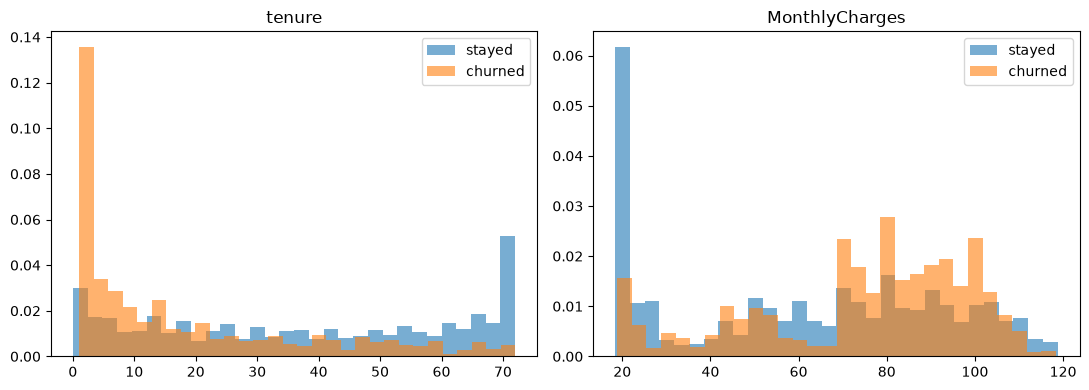

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges"], strict=True):
    for label, grp in train.groupby("Churn"):
        ax.hist(grp[col], bins=30, alpha=0.6, density=True, label="churned" if label else "stayed")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()

**Findings:**

- Churn is concentrated early: 52.3% of customers in their first 6 months churned, against 9.6% of those with 49-72 months.
- Churners have a median tenure of 10 months versus 37 for customers who stayed.
- Churners pay more per month (median $79.75 vs $64.38).
- `TotalCharges` is largely tenure x monthly charge (correlation with tenure 0.834), so it adds little new information. It is kept because the models handle correlated inputs, but its SHAP importance should be read together with tenure.

### 7. Support services and demographics

In [12]:
for col in ["TechSupport", "OnlineSecurity", "SeniorCitizen", "Partner", "PaperlessBilling", "gender"]:
    display(rate(col))

,churn_rate,customers
TechSupport,,
No,0.4179,2082
No internet service,0.0727,908
Yes,0.1498,1235


,churn_rate,customers
OnlineSecurity,,
No,0.4204,2103
No internet service,0.0727,908
Yes,0.1409,1214


,churn_rate,customers
SeniorCitizen,,
No,0.2374,3534
Yes,0.4081,691


,churn_rate,customers
Partner,,
No,0.3335,2189
Yes,0.1920,2036


,churn_rate,customers
PaperlessBilling,,
No,0.1623,1701
Yes,0.3348,2524


,churn_rate,customers
gender,,
Female,0.2709,2086
Male,0.2599,2139


**Findings:**

- Internet customers without tech support churn at 41.8% vs 15.0% with it; without online security 42.0% vs 14.1%.
- Senior citizens churn at 40.8% vs 23.7% for others.
- Customers without a partner churn at 33.4% vs 19.2% with one.
- Paperless billing: 33.5% vs 16.2%.
- Gender makes almost no difference (27.1% female vs 26.0% male).

These are associations. Customers who buy tech support may simply be more committed, so this does not show that giving people tech support would stop them leaving.

### Implications for modelling

1. Use a stratified split and PR-AUC because the classes are 26.5% / 73.5%.
2. Contract, tenure and internet type will dominate any model; the interesting question is who churns *despite* a long contract, which is where we expect misses.
3. One-hot encode categoricals and scale numerics inside a Pipeline fit on training data only.

## Part 2 · Tune and compare models

**Input:** train and validation splits. 

Every model is a `Pipeline(preprocess -> classifier)` (defined above), so the scaler and one-hot encoder
only ever see training rows, and cross-validation refits them inside each fold.

### Tune with 5-fold CV on training, add a calibrated copy of each family

In [13]:
cfg = load_config()
seed = cfg["seed"]
X_tr, y_tr = xy(load_split("train"))
X_va, y_va = xy(load_split("val"))
cv = StratifiedKFold(n_splits=cfg["cv"]["folds"], shuffle=True, random_state=seed)
MODELS_DIR.mkdir(exist_ok=True)
IMG.mkdir(parents=True, exist_ok=True)

fitted: dict[str, object] = {}
cv_scores: dict[str, float] = {}
best_params: dict[str, dict] = {}

# Unweighted logistic regression, to show what class weights change.
base = make_pipeline("logreg_unweighted", seed)
gs = GridSearchCV(base, PARAM_GRIDS["logreg"], scoring=cfg["cv"]["scoring"], cv=cv, n_jobs=-1)
gs.fit(X_tr, y_tr)
fitted["logreg_unweighted"], cv_scores["logreg_unweighted"] = gs.best_estimator_, gs.best_score_
best_params["logreg_unweighted"] = gs.best_params_

for name in ["logreg", "random_forest", "gradient_boosting"]:
    gs = GridSearchCV(make_pipeline(name, seed), PARAM_GRIDS[name], scoring=cfg["cv"]["scoring"], cv=cv, n_jobs=-1)
    gs.fit(X_tr, y_tr)
    fitted[name], cv_scores[name], best_params[name] = gs.best_estimator_, gs.best_score_, gs.best_params_
    print(f"{name}: CV PR-AUC {gs.best_score_:.4f} with {gs.best_params_}")

    # Calibrated copy: sigmoid calibration fit with internal CV on the training set.
    cal = CalibratedClassifierCV(gs.best_estimator_, method="sigmoid", cv=cv)
    cal.fit(X_tr, y_tr)
    fitted[f"{name}_calibrated"] = cal
    cv_scores[f"{name}_calibrated"] = np.nan

logreg: CV PR-AUC 0.6653 with {'model__C': 10.0}


random_forest: CV PR-AUC 0.6767 with {'model__max_depth': 10, 'model__max_features': 0.5, 'model__min_samples_leaf': 20}


gradient_boosting: CV PR-AUC 0.6716 with {'model__l2_regularization': 1.0, 'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__max_iter': 100}


#### Score every model on validation and show the report

In [14]:
rows, preds = [], {"y": y_va.to_numpy()}
for name, model in fitted.items():
    p = model.predict_proba(X_va)[:, 1]
    preds[name] = p
    rows.append({"model": name, "cv_pr_auc": cv_scores[name], **evaluate(y_va.to_numpy(), p)})
    joblib.dump(model, MODELS_DIR / f"{name}.joblib")

results = pd.DataFrame(rows).sort_values("pr_auc", ascending=False)
majority_acc = 1 - y_va.mean()
results.to_csv(DOCS / "results.csv", index=False)
pd.DataFrame(preds).to_csv(PROCESSED / "val_predictions.csv", index=False)
(DOCS / "best_params.json").write_text(json.dumps(best_params, indent=2, default=str))

md = [
    "# Model comparison (validation set, threshold 0.5)",
    "",
    f"Validation rows: {len(y_va):,}; churn rate {y_va.mean():.4f}. "
    f"A model that predicts 'no churn' for everyone scores accuracy {majority_acc:.4f} "
    "with recall 0, which is why accuracy is not used to pick a model.",
    "",
    "`cv_pr_auc` = mean 5-fold CV PR-AUC on the training set for the tuned settings "
    "(blank for calibrated wrappers, which reuse those settings).",
    "",
    results.to_markdown(index=False, floatfmt=".4f"),
    "",
]
show("\n".join(md))
print(results.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# Model comparison (validation set, threshold 0.5)

Validation rows: 1,409; churn rate 0.2654. A model that predicts 'no churn' for everyone scores accuracy 0.7346 with recall 0, which is why accuracy is not used to pick a model.

`cv_pr_auc` = mean 5-fold CV PR-AUC on the training set for the tuned settings (blank for calibrated wrappers, which reuse those settings).

| model                        |   cv_pr_auc |   precision |   recall |     f1 |   pr_auc |   roc_auc |   brier |   accuracy |
|:-----------------------------|------------:|------------:|---------:|-------:|---------:|----------:|--------:|-----------:|
| gradient_boosting_calibrated |    nan      |      0.6844 |   0.4813 | 0.5651 |   0.6509 |    0.8407 |  0.1369 |     0.8034 |
| logreg_calibrated            |    nan      |      0.6678 |   0.5321 | 0.5923 |   0.6436 |    0.8370 |  0.1380 |     0.8055 |
| logreg                       |      0.6653 |      0.5122 |   0.7861 | 0.6203 |   0.6432 |    0.8369 |  0.1679 |     0.7445 |
| logreg_unweighted            |      0.6679 |      0.6612 |   0.5374 | 0.5929 |   0.6428 |    0.8366 |  0.1378 |     0.8041 |
| gradient_boosting            |      0.6716 |      0.5034 |   0.7834 | 0.6130 |   0.6423 |    0.8379 |  0.1653 |     0.7374 |
| random_forest                |      0.6767 |      0.5131 |   0.7861 | 0.6209 |   0.6423 |    0.8377 |  0.1638 |     0.7452 |
| random_forest_calibrated     |    nan      |      0.6431 |   0.5107 | 0.5693 |   0.6414 |    0.8385 |  0.1373 |     0.7949 |


                       model  cv_pr_auc  precision  recall     f1  pr_auc  roc_auc  brier  accuracy
gradient_boosting_calibrated        NaN     0.6844  0.4813 0.5651  0.6509   0.8407 0.1369    0.8034
           logreg_calibrated        NaN     0.6678  0.5321 0.5923  0.6436   0.8370 0.1380    0.8055
                      logreg     0.6653     0.5122  0.7861 0.6203  0.6432   0.8369 0.1679    0.7445
           logreg_unweighted     0.6679     0.6612  0.5374 0.5929  0.6428   0.8366 0.1378    0.8041
           gradient_boosting     0.6716     0.5034  0.7834 0.6130  0.6423   0.8379 0.1653    0.7374
               random_forest     0.6767     0.5131  0.7861 0.6209  0.6423   0.8377 0.1638    0.7452
    random_forest_calibrated        NaN     0.6431  0.5107 0.5693  0.6414   0.8385 0.1373    0.7949


#### Calibration: do the scores mean what they say?

Saved calibration plot


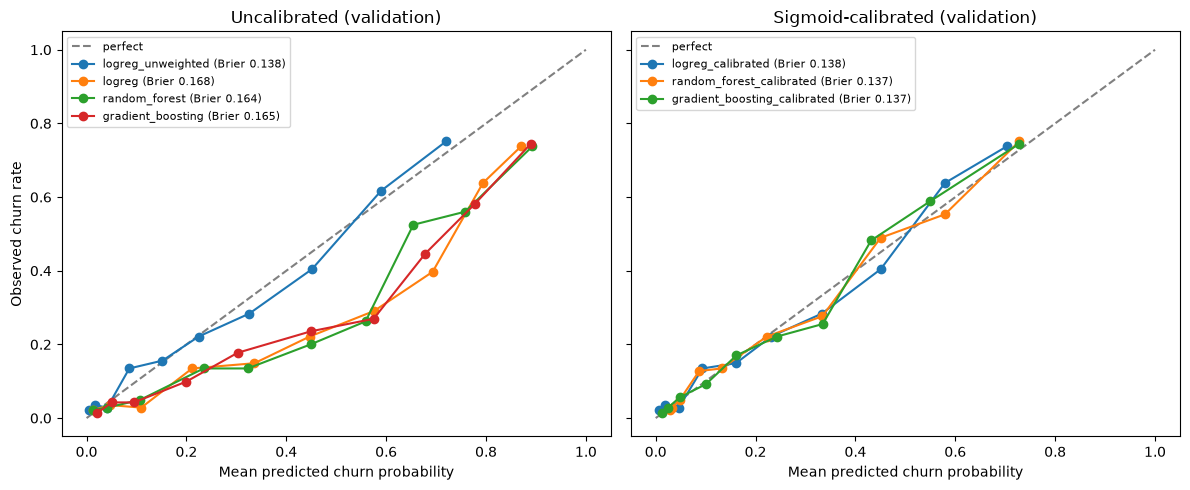

In [15]:
# Reliability curves.
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, names, title in [
    (axes[0], ["logreg_unweighted", "logreg", "random_forest", "gradient_boosting"], "Uncalibrated"),
    (
        axes[1],
        ["logreg_calibrated", "random_forest_calibrated", "gradient_boosting_calibrated"],
        "Sigmoid-calibrated",
    ),
]:
    ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
    for name in names:
        frac, mean_p = calibration_curve(y_va, preds[name], n_bins=10, strategy="quantile")
        brier = brier_score_loss(y_va, preds[name])
        ax.plot(mean_p, frac, marker="o", label=f"{name} (Brier {brier:.3f})")
    ax.set_title(f"{title} (validation)")
    ax.set_xlabel("Mean predicted churn probability")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Observed churn rate")
fig.tight_layout()
fig.savefig(IMG / "calibration.png", dpi=120)
print("Saved calibration plot")

## Part 3 · Choose the model and threshold by expected value

**Input:** `data/processed/val_predictions.csv` (validation only). 

A churn model only becomes a decision once you say who gets an offer. Using the assumptions in
`config/config.yaml`, each targeted customer is worth:

- churner: `success_rate x customer_value - offer_cost`
- non-churner: `-offer_cost`
- anyone not targeted: 0 (we do nothing)

Three analyses, all on validation:

1. **Pick model + threshold** with the highest expected value (EV), and bootstrap whether the winner is really better.
2. **Sensitivity grid**: how the best threshold moves across 144 offer-cost x customer-value combinations.
3. **Per-customer value**: rank by `p x customer value` instead of `p` alone.

The EV functions (`expected_value`, `best_threshold`, `realised_value`...) are defined in the scoring helpers above.

## Part 1: model and threshold

Total EV at a threshold is the sum over targeted validation customers. The
threshold that maximises it is chosen per model; the model with the highest
EV wins. A sensitivity grid shows how the threshold moves with the assumptions.

#### Best threshold for every model

In [16]:
cfg = load_config()
econ = cfg["economics"]
preds = pd.read_csv(PROCESSED / "val_predictions.csv")
y = preds.pop("y").to_numpy()

rows = []
for name in preds.columns:
    p = preds[name].to_numpy()
    t, ev = best_threshold(y, p, econ)
    f1_best_t = THRESHOLDS[int(np.argmax([f1_score(y, (p >= tt).astype(int)) for tt in THRESHOLDS]))]
    rows.append(
        {
            "model": name,
            "ev_best_threshold": t,
            "ev_at_best": ev,
            "ev_at_0.5": expected_value(
                y, p, 0.5, econ["offer_cost"], econ["customer_value"], econ["offer_success_rate"]
            ),
            "f1_at_0.5": f1_score(y, (p >= 0.5).astype(int)),
            "f1_best_threshold": float(f1_best_t),
            "ev_at_f1_best": expected_value(
                y, p, f1_best_t, econ["offer_cost"], econ["customer_value"], econ["offer_success_rate"]
            ),
            "targeted_at_best": int((p >= t).sum()),
        }
    )
table = pd.DataFrame(rows).sort_values("ev_at_best", ascending=False)
chosen = table.iloc[0]
best_f1_model = table.sort_values("f1_at_0.5", ascending=False).iloc[0]["model"]

#### Reference policies and one-at-a-time sensitivity

In [17]:
# Reference policies on validation.
n_churn, n = int(y.sum()), len(y)
target_all = expected_value(y, np.ones(n), 0.5, econ["offer_cost"], econ["customer_value"], econ["offer_success_rate"])
perfect = n_churn * (econ["offer_success_rate"] * econ["customer_value"] - econ["offer_cost"])
break_even = econ["offer_cost"] / (econ["offer_success_rate"] * econ["customer_value"])

# Sensitivity: vary one assumption at a time around the base case, and the full grid.
p_chosen = preds[chosen["model"]].to_numpy()
sens_rows = []
sens_grid = cfg["sensitivity"]
for cost, value, rate in itertools.product(
    sens_grid["offer_cost"], sens_grid["customer_value"], sens_grid["offer_success_rate"]
):
    e = {"offer_cost": cost, "customer_value": value, "offer_success_rate": rate}
    t, ev = best_threshold(y, p_chosen, e)
    sens_rows.append(
        {
            **e,
            "break_even_p": cost / (rate * value),
            "best_threshold": t,
            "ev_val": ev,
            "targeted": int((p_chosen >= t).sum()) if ev > 0 else 0,
        }
    )
sens = pd.DataFrame(sens_rows)
one_at_a_time = sens[
    ((sens["customer_value"] == econ["customer_value"]) & (sens["offer_success_rate"] == econ["offer_success_rate"]))
    | ((sens["offer_cost"] == econ["offer_cost"]) & (sens["offer_success_rate"] == econ["offer_success_rate"]))
    | ((sens["offer_cost"] == econ["offer_cost"]) & (sens["customer_value"] == econ["customer_value"]))
].drop_duplicates()

#### Is the winner really better?

In [18]:
# How sure are we the chosen model beats the others? Bootstrap validation rows
# and recompute the EV gap at each model's fixed chosen threshold.
rng = np.random.default_rng(cfg["seed"])
boot_idx = [rng.integers(0, n, n) for _ in range(1000)]
args = (econ["offer_cost"], econ["customer_value"], econ["offer_success_rate"])
boot_rows = []
for _, other in table.iloc[1:].iterrows():
    p_o = preds[other["model"]].to_numpy()
    diffs = np.array(
        [
            expected_value(y[i], p_chosen[i], chosen["ev_best_threshold"], *args)
            - expected_value(y[i], p_o[i], other["ev_best_threshold"], *args)
            for i in boot_idx
        ]
    )
    boot_rows.append(
        {
            "vs_model": other["model"],
            "mean_ev_gap": diffs.mean(),
            "ci95_low": np.percentile(diffs, 2.5),
            "ci95_high": np.percentile(diffs, 97.5),
            "share_chosen_better": (diffs > 0).mean(),
        }
    )
boot = pd.DataFrame(boot_rows)

#### Save the choice and show the report

In [19]:
out = {
    "chosen_model": chosen["model"],
    "threshold": chosen["ev_best_threshold"],
    "val_ev": chosen["ev_at_best"],
    "best_f1_model_at_0.5": best_f1_model,
    "economics": econ,
    "break_even_probability": break_even,
    "val_ev_target_everyone": target_all,
    "val_ev_perfect_model": perfect,
    "val_rows": n,
    "val_churners": n_churn,
}
(DOCS / "threshold.json").write_text(json.dumps(out, indent=2, default=float))

md = [
    "# Expected-value threshold (validation set)",
    "",
    f"Assumptions (config/config.yaml): offer cost ${econ['offer_cost']}, value of a lost customer "
    f"${econ['customer_value']}, offer success rate {econ['offer_success_rate']:.0%}.",
    f"Targeting a churner is worth {econ['offer_success_rate']} x {econ['customer_value']} - "
    f"{econ['offer_cost']} = ${econ['offer_success_rate'] * econ['customer_value'] - econ['offer_cost']:.0f}; "
    f"targeting a non-churner costs ${econ['offer_cost']}. With perfectly calibrated probabilities the "
    f"break-even churn probability is {break_even:.2f}.",
    "",
    "## Per model",
    "",
    table.to_markdown(index=False, floatfmt=".4f"),
    "",
    f"**Chosen:** `{chosen['model']}` at threshold **{chosen['ev_best_threshold']:.2f}**, "
    f"validation EV **${chosen['ev_at_best']:,.0f}** for {n:,} customers. "
    f"Highest F1 at 0.5: `{best_f1_model}`.",
    "",
    "## Is the winner really better? (1,000 bootstrap resamples of validation)",
    "",
    "EV gap = chosen model minus the other model, each at its own threshold above. "
    "Thresholds are held fixed, so this understates the uncertainty slightly.",
    "",
    boot.to_markdown(index=False, floatfmt=".2f"),
    "",
    "## Reference policies (validation)",
    "",
    "- Target nobody: $0",
    f"- Target everyone: ${target_all:,.0f}",
    f"- Perfect model (target exactly the {n_churn} churners): ${perfect:,.0f}",
    "",
    "## Sensitivity of the chosen model's threshold (one assumption varied at a time)",
    "",
    one_at_a_time.to_markdown(index=False, floatfmt=".2f"),
    "",
    "Full 27-combination grid: saved to `data/results/sensitivity_grid.csv`.",
    "",
]
show("\n".join(md))
sens.to_csv(DOCS / "sensitivity_grid.csv", index=False)
print("\n".join(md))

# Expected-value threshold (validation set)

Assumptions (config/config.yaml): offer cost $100, value of a lost customer $1000, offer success rate 40%.
Targeting a churner is worth 0.4 x 1000 - 100 = $300; targeting a non-churner costs $100. With perfectly calibrated probabilities the break-even churn probability is 0.25.

## Per model

| model                        |   ev_best_threshold |   ev_at_best |   ev_at_0.5 |   f1_at_0.5 |   f1_best_threshold |   ev_at_f1_best |   targeted_at_best |
|:-----------------------------|--------------------:|-------------:|------------:|------------:|--------------------:|----------------:|-------------------:|
| random_forest                |              0.4500 |   61900.0000 |  60300.0000 |      0.6209 |              0.6200 |      60100.0000 |                633 |
| gradient_boosting_calibrated |              0.3600 |   61600.0000 |  45700.0000 |      0.5651 |              0.3600 |      61600.0000 |                456 |
| random_forest_calibrated     |              0.2000 |   61400.0000 |  46700.0000 |      0.5693 |              0.3700 |      61300.0000 |                662 |
| logreg                       |              0.4600 |   61000.0000 |  60200.0000 |      0.6203 |              0.6200 |      58800.0000 |                614 |
| logreg_calibrated            |              0.2400 |   60900.0000 |  49800.0000 |      0.5923 |              0.3700 |      59700.0000 |                615 |
| logreg_unweighted            |              0.2600 |   60600.0000 |  50000.0000 |      0.5929 |              0.3700 |      59100.0000 |                578 |
| gradient_boosting            |              0.5900 |   60500.0000 |  59000.0000 |      0.6130 |              0.6100 |      60200.0000 |                475 |

**Chosen:** `random_forest` at threshold **0.45**, validation EV **$61,900** for 1,409 customers. Highest F1 at 0.5: `random_forest`.

## Is the winner really better? (1,000 bootstrap resamples of validation)

EV gap = chosen model minus the other model, each at its own threshold above. Thresholds are held fixed, so this understates the uncertainty slightly.

| vs_model                     |   mean_ev_gap |   ci95_low |   ci95_high |   share_chosen_better |
|:-----------------------------|--------------:|-----------:|------------:|----------------------:|
| gradient_boosting_calibrated |        280.80 |   -4100.00 |     5200.00 |                  0.53 |
| random_forest_calibrated     |        482.10 |   -1300.00 |     2102.50 |                  0.69 |
| logreg                       |        792.20 |   -2402.50 |     4002.50 |                  0.66 |
| logreg_calibrated            |        893.60 |   -2400.00 |     4100.00 |                  0.69 |
| logreg_unweighted            |       1213.20 |   -2100.00 |     4500.00 |                  0.75 |
| gradient_boosting            |       1330.10 |   -3002.50 |     5800.00 |                  0.72 |

## Reference policies (validation)

- Target nobody: $0
- Target everyone: $8,700
- Perfect model (target exactly the 374 churners): $112,200

## Sensitivity of the chosen model's threshold (one assumption varied at a time)

|   offer_cost |   customer_value |   offer_success_rate |   break_even_p |   best_threshold |    ev_val |   targeted |
|-------------:|-----------------:|---------------------:|---------------:|-----------------:|----------:|-----------:|
|        50.00 |          1000.00 |                 0.40 |           0.12 |             0.23 |  95750.00 |     925.00 |
|       100.00 |           500.00 |                 0.40 |           0.50 |             0.62 |   9700.00 |     407.00 |
|       100.00 |          1000.00 |                 0.20 |           0.50 |             0.62 |   9700.00 |     407.00 |
|       100.00 |          1000.00 |                 0.40 |           0.25 |             0.45 |  61900.00 |     633.00 |
|       100.00 |          1000.00 |                 0.60 |           0.17 |             0.42 | 124800.00 |     666.00 |
|       100.00 |          2000.00 |                 0.40 |           0.12 |             0.23 | 191500.00 |     925.00 |
|       200.00 |          1000.00 |                 0.40 |           0.50 |             0.62 |  19400.00 |     407.00 |

Full 27-combination grid: saved to `data/results/sensitivity_grid.csv`.


# Expected-value threshold (validation set)

Assumptions (config/config.yaml): offer cost $100, value of a lost customer $1000, offer success rate 40%.
Targeting a churner is worth 0.4 x 1000 - 100 = $300; targeting a non-churner costs $100. With perfectly calibrated probabilities the break-even churn probability is 0.25.

## Per model

| model                        |   ev_best_threshold |   ev_at_best |   ev_at_0.5 |   f1_at_0.5 |   f1_best_threshold |   ev_at_f1_best |   targeted_at_best |
|:-----------------------------|--------------------:|-------------:|------------:|------------:|--------------------:|----------------:|-------------------:|
| random_forest                |              0.4500 |   61900.0000 |  60300.0000 |      0.6209 |              0.6200 |      60100.0000 |                633 |
| gradient_boosting_calibrated |              0.3600 |   61600.0000 |  45700.0000 |      0.5651 |              0.3600 |      61600.0000 |                456 |
| random_forest_calibrate

#### EV curves

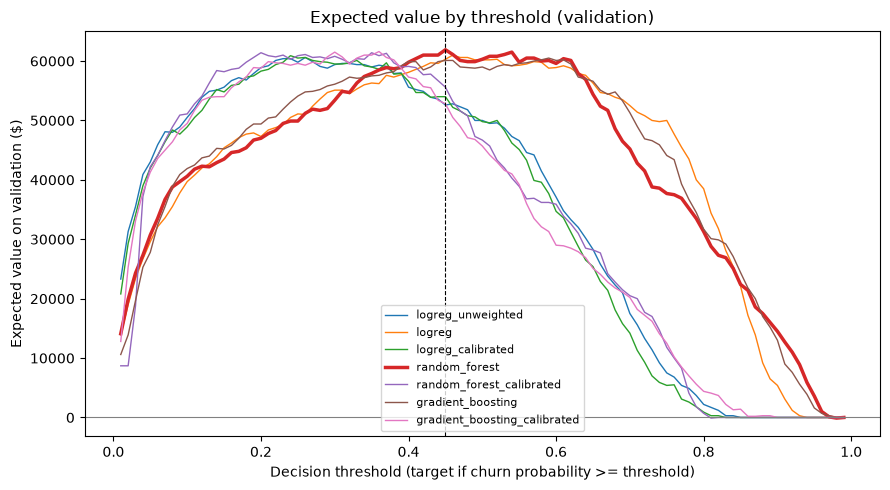

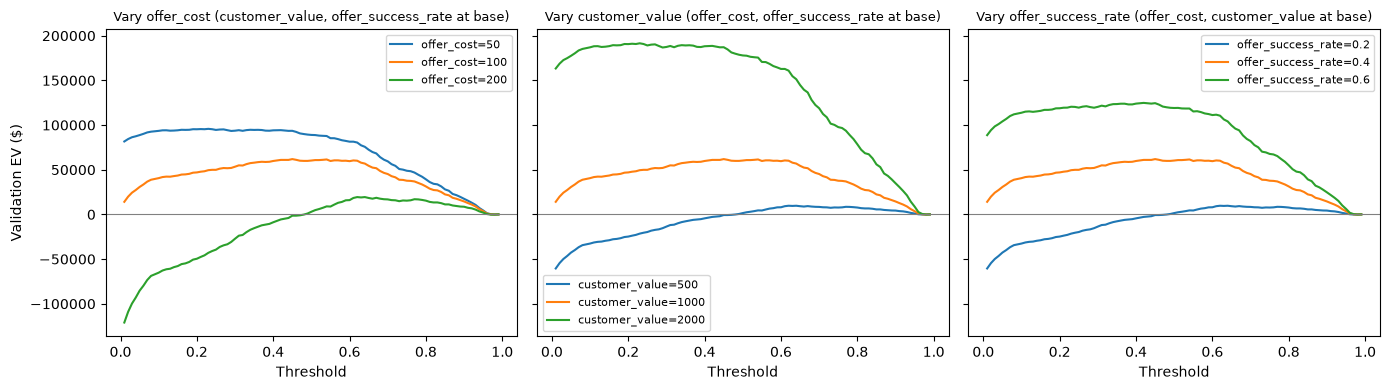

In [20]:
# EV curves for the uncalibrated and calibrated version of each family.
fig, ax = plt.subplots(figsize=(9, 5))
for name in preds.columns:
    ax.plot(
        THRESHOLDS,
        ev_curve(y, preds[name].to_numpy(), econ),
        label=name,
        linewidth=2.5 if name == chosen["model"] else 1,
    )
ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(chosen["ev_best_threshold"], color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("Decision threshold (target if churn probability >= threshold)")
ax.set_ylabel("Expected value on validation ($)")
ax.set_title("Expected value by threshold (validation)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(IMG / "ev_curve.png", dpi=120)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, key in zip(axes, ["offer_cost", "customer_value", "offer_success_rate"], strict=False):
    others = [k for k in ["offer_cost", "customer_value", "offer_success_rate"] if k != key]
    for v in sens_grid[key]:
        e = {**econ, key: v}
        ax.plot(THRESHOLDS, ev_curve(y, p_chosen, e), label=f"{key}={v}")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(f"Vary {key} ({', '.join(others)} at base)", fontsize=9)
    ax.set_xlabel("Threshold")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Validation EV ($)")
fig.tight_layout()
fig.savefig(IMG / "sensitivity.png", dpi=120)

---
## Part 2: sensitivity to offer cost and customer value

Extends the 27-point grid in Part 1: here offer cost and the value of a
lost customer each take 12 values (success rate fixed at the base case), and
for every combination we find the threshold that maximises validation EV. Done
for the chosen model and for its calibrated twin, to show how calibration
changes the link between the optimal threshold and the theoretical break-even.

In [21]:
COSTS = np.arange(25, 301, 25)
VALUES = np.arange(250, 3001, 250)

In [22]:
def grid(y: np.ndarray, p: np.ndarray, rate: float) -> pd.DataFrame:
    """Best threshold and EV for every (offer_cost, customer_value) pair."""
    rows = []
    for cost in COSTS:
        for value in VALUES:
            t, ev = best_threshold(y, p, {"offer_cost": cost, "customer_value": value, "offer_success_rate": rate})
            target = ev > 0
            rows.append(
                {
                    "offer_cost": int(cost),
                    "customer_value": int(value),
                    "break_even_p": cost / (rate * value),
                    "best_threshold": t if target else np.nan,
                    "best_ev": max(ev, 0.0),
                    "targeted": int((p >= t).sum()) if target else 0,
                }
            )
    return pd.DataFrame(rows)

In [23]:
def describe(g: pd.DataFrame, rate: float) -> dict:
    """Summary numbers used in the write-up."""
    act = g.dropna(subset=["best_threshold"])
    feasible = act[act["break_even_p"] < 1]
    return {
        "cells": len(g),
        "target_nobody": int(g["best_threshold"].isna().sum()),
        "no_margin": int((rate * g["customer_value"] <= g["offer_cost"]).sum()),
        "threshold_min": float(act["best_threshold"].min()),
        "threshold_max": float(act["best_threshold"].max()),
        "ev_max": float(g["best_ev"].max()),
        "corr_threshold_breakeven": float(feasible["best_threshold"].corr(feasible["break_even_p"])),
        "mean_abs_gap_to_breakeven": float((feasible["best_threshold"] - feasible["break_even_p"]).abs().mean()),
        "mean_signed_gap_to_breakeven": float((feasible["best_threshold"] - feasible["break_even_p"]).mean()),
    }

In [24]:
def heatmaps(g: pd.DataFrame, title: str, axes) -> None:
    """Draw best-threshold and best-EV heatmaps on two axes."""
    t = g.pivot(index="customer_value", columns="offer_cost", values="best_threshold").sort_index(ascending=False)
    ev = (
        g.pivot(index="customer_value", columns="offer_cost", values="best_ev").sort_index(ascending=False) / 1000 + 0.0
    )
    for ax, mat, label, fmt, cmap in [
        (axes[0], t, "Best threshold (blank = target nobody)", "{:.2f}", "viridis"),
        (axes[1], ev, "Best validation EV ($k)", "{:.0f}", "Greens"),
    ]:
        im = ax.imshow(mat.to_numpy(dtype=float), cmap=cmap, aspect="auto")
        ax.set_xticks(range(len(mat.columns)), mat.columns, fontsize=7)
        ax.set_yticks(range(len(mat.index)), mat.index, fontsize=7)
        ax.set_xlabel("Offer cost ($)")
        ax.set_ylabel("Value of a lost customer ($)")
        ax.set_title(f"{title}: {label}", fontsize=9)
        for i in range(mat.shape[0]):
            for j in range(mat.shape[1]):
                v = mat.iat[i, j]
                if not np.isnan(v):
                    ax.text(
                        j,
                        i,
                        fmt.format(v),
                        ha="center",
                        va="center",
                        fontsize=5.5,
                        color="white" if cmap == "viridis" else "black",
                    )
        plt.colorbar(im, ax=ax, fraction=0.046)

#### Run the grid for the chosen model and its calibrated twin

# Sensitivity: offer cost x customer value (validation)

For each of 12 offer costs ($25-$300) x 12 customer values ($250-$3,000), with the success rate fixed at 40%, the threshold with the highest validation EV is found. The 27-point grid that also varies the success rate is in Part 1 above.

## What it shows

- **Chosen model (`random_forest`):** the best threshold ranges from 0.02 to 0.92 across the grid. In 16 of 144 cells no threshold makes money, so the right policy is to send no offers. In 15 of them a saved customer is worth no more than the offer (40% x value <= cost), so even a perfect model couldn't profit; in the other 1 the margin per saved churner is positive but too thin for this model's precision.
- Base case ($100 offer, $1,000 value): threshold 0.45, EV $61,900, 633 customers targeted.
- **The threshold tracks the break-even probability** (cost / (rate x value)): correlation 0.93 for the chosen model, 0.98 for `random_forest_calibrated`. But the chosen model's thresholds sit on average +0.18 from break-even (mean absolute gap 0.18), while the calibrated model's sit -0.00 (absolute 0.03). Class weights inflate the uncalibrated model's probabilities, so its thresholds must be read on its own scale; with calibrated scores the textbook rule is closer.
- The best achievable EV ranges from $0 to $414,175 (cheapest offer, highest customer value) on the 1,409 validation customers, so the assumptions move the dollar figure far more than the choice of model does.

## How to use it

Pick the row for your real customer value and the column for your real offer cost and read off the threshold. If the cell is blank, don't run the campaign at that price. Because the assumptions are guesses, the useful output is the *shape*: the decision is stable across neighbouring cells and flips to 'target nobody' only when offers become expensive relative to customer value.

## Best threshold, chosen model (`random_forest`); blank = target nobody

|   customer_value |   25 |   50 |   75 |    100 |    125 |    150 |    175 |    200 |    225 |    250 |    275 |    300 |
|-----------------:|-----:|-----:|-----:|-------:|-------:|-------:|-------:|-------:|-------:|-------:|-------:|-------:|
|             3000 | 0.02 | 0.11 | 0.11 |   0.19 |   0.19 |   0.23 |   0.42 |   0.42 |   0.45 |   0.45 |   0.45 |   0.45 |
|             2750 | 0.03 | 0.11 | 0.11 |   0.19 |   0.23 |   0.23 |   0.42 |   0.42 |   0.45 |   0.45 |   0.45 |   0.54 |
|             2500 | 0.03 | 0.11 | 0.11 |   0.19 |   0.23 |   0.42 |   0.42 |   0.45 |   0.45 |   0.45 |   0.54 |   0.61 |
|             2250 | 0.11 | 0.11 | 0.19 |   0.23 |   0.36 |   0.42 |   0.45 |   0.45 |   0.45 |   0.61 |   0.61 |   0.62 |
|             2000 | 0.11 | 0.11 | 0.19 |   0.23 |   0.42 |   0.45 |   0.45 |   0.45 |   0.61 |   0.62 |   0.62 |   0.62 |
|             1750 | 0.11 | 0.11 | 0.23 |   0.42 |   0.42 |   0.45 |   0.45 |   0.61 |   0.62 |   0.62 |   0.62 |   0.62 |
|             1500 | 0.11 | 0.19 | 0.23 |   0.42 |   0.45 |   0.45 |   0.61 |   0.62 |   0.62 |   0.62 |   0.62 |   0.62 |
|             1250 | 0.11 | 0.19 | 0.42 |   0.45 |   0.45 |   0.61 |   0.62 |   0.62 |   0.62 |   0.62 |   0.78 |   0.78 |
|             1000 | 0.11 | 0.23 | 0.45 |   0.45 |   0.62 |   0.62 |   0.62 |   0.62 |   0.78 |   0.78 |   0.90 |   0.90 |
|              750 | 0.19 | 0.42 | 0.45 |   0.62 |   0.62 |   0.62 |   0.78 |   0.80 |   0.90 |   0.92 | nan    | nan    |
|              500 | 0.23 | 0.45 | 0.62 |   0.62 |   0.78 |   0.90 |   0.92 | nan    | nan    | nan    | nan    | nan    |
|              250 | 0.45 | 0.62 | 0.90 | nan    | nan    | nan    | nan    | nan    | nan    | nan    | nan    | nan    |


{
  "random_forest": {
    "cells": 144,
    "target_nobody": 16,
    "no_margin": 15,
    "threshold_min": 0.02,
    "threshold_max": 0.92,
    "ev_max": 414175.0,
    "corr_threshold_breakeven": 0.9309463929055655,
    "mean_abs_gap_to_breakeven": 0.18184160240800867,
    "mean_signed_gap_to_breakeven": 0.18182858157467532
  },
  "random_forest_calibrated": {
    "cells": 144,
    "target_nobody": 16,
    "no_margin": 15,
    "threshold_min": 0.03,
    "threshold_max": 0.75,
    "ev_max": 413900.0,
    "corr_threshold_breakeven": 0.9801602356722839,
    "mean_abs_gap_to_breakeven": 0.029828418109668107,
    "mean_signed_gap_to_breakeven": -0.003952668425324671
  }
}


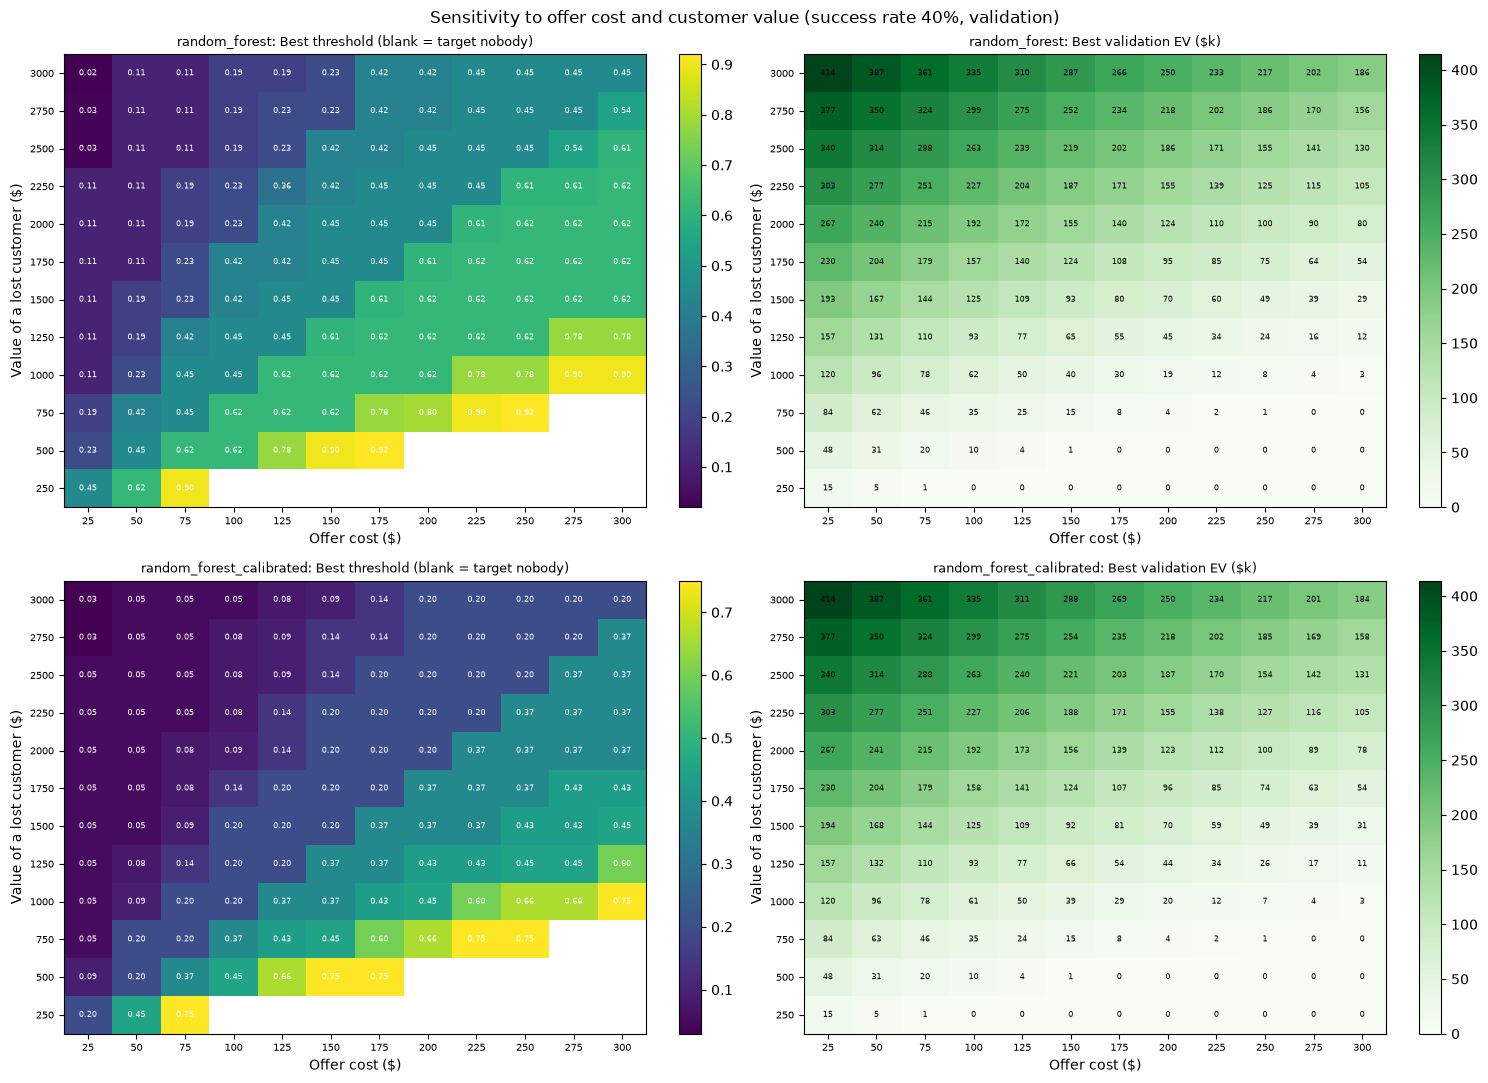

In [25]:
cfg = load_config()
rate = cfg["economics"]["offer_success_rate"]
choice = json.loads((DOCS / "threshold.json").read_text())
chosen = choice["chosen_model"]
family = chosen.removesuffix("_calibrated")
twin = family if chosen.endswith("_calibrated") else f"{family}_calibrated"
preds = pd.read_csv(PROCESSED / "val_predictions.csv")
y = preds["y"].to_numpy()

results = {name: grid(y, preds[name].to_numpy(), rate) for name in (chosen, twin)}
stats = {name: describe(g, rate) for name, g in results.items()}

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for row, (name, g) in zip(axes, results.items(), strict=False):
    heatmaps(g, name, row)
fig.suptitle(f"Sensitivity to offer cost and customer value (success rate {rate:.0%}, validation)")
fig.tight_layout()
fig.savefig(IMG / "sensitivity_heatmap.png", dpi=110)

c, w = stats[chosen], stats[twin]
base = results[chosen].query("offer_cost == 100 and customer_value == 1000").iloc[0]
table = results[chosen].pivot(index="customer_value", columns="offer_cost", values="best_threshold")
md = [
    "# Sensitivity: offer cost x customer value (validation)",
    "",
    "For each of "
    f"{len(COSTS)} offer costs (${COSTS.min()}-${COSTS.max()}) x {len(VALUES)} customer values "
    f"(${VALUES.min():,}-${VALUES.max():,}), with the success rate fixed at {rate:.0%}, the threshold "
    "with the highest validation EV is found. The 27-point grid that also varies the success rate is in "
    "Part 1 above.",
    "",
    "## What it shows",
    "",
    f"- **Chosen model (`{chosen}`):** the best threshold ranges from {c['threshold_min']:.2f} to "
    f"{c['threshold_max']:.2f} across the grid. In {c['target_nobody']} of {c['cells']} cells no threshold "
    "makes money, so the right policy is to send no offers. In "
    f"{c['no_margin']} of them a saved customer is worth no more than the offer ({rate:.0%} x value <= cost), "
    "so even a perfect model couldn't profit; in the other "
    f"{c['target_nobody'] - c['no_margin']} the margin per saved churner is positive but too thin for this "
    "model's precision.",
    f"- Base case ($100 offer, $1,000 value): threshold {base['best_threshold']:.2f}, "
    f"EV ${base['best_ev']:,.0f}, {int(base['targeted'])} customers targeted.",
    f"- **The threshold tracks the break-even probability** (cost / (rate x value)): correlation "
    f"{c['corr_threshold_breakeven']:.2f} for the chosen model, {w['corr_threshold_breakeven']:.2f} for "
    f"`{twin}`. But the chosen model's thresholds sit on average {c['mean_signed_gap_to_breakeven']:+.2f} "
    f"from break-even (mean absolute gap {c['mean_abs_gap_to_breakeven']:.2f}), while the calibrated "
    f"model's sit {w['mean_signed_gap_to_breakeven']:+.2f} (absolute {w['mean_abs_gap_to_breakeven']:.2f}). "
    "Class weights inflate the uncalibrated model's probabilities, so its thresholds must be read on its own "
    "scale; with calibrated scores the textbook rule is closer.",
    f"- The best achievable EV ranges from $0 to ${c['ev_max']:,.0f} (cheapest offer, highest customer value) "
    "on the 1,409 validation customers, so the assumptions move the dollar figure far more than the "
    "choice of model does.",
    "",
    "## How to use it",
    "",
    "Pick the row for your real customer value and the column for your real offer cost and read off the "
    "threshold. If the cell is blank, don't run the campaign at that price. Because the assumptions are "
    "guesses, the useful output is the *shape*: the decision is stable across neighbouring cells and flips "
    "to 'target nobody' only when offers become expensive relative to customer value.",
    "",
    f"## Best threshold, chosen model (`{chosen}`); blank = target nobody",
    "",
    table.sort_index(ascending=False).to_markdown(floatfmt=".2f"),
    "",
]
show("\n".join(md))
print(json.dumps(stats, indent=2))

---
## Part 3: per-customer value

Value of losing customer i:  V_i = MonthlyCharges_i * value_months
Realised value of a targeting decision, summed over targeted customers:
    churner:      success_rate * V_i - offer_cost
    non-churner:  - offer_cost

Two rules are compared under these economics:
  probability   target if p_i >= t                   (ignores value; the earlier approach)
  value         target if p_i * V_i >= t_dollars     (expected value at risk)

Each rule's threshold is chosen on validation. Part 4 scores the test set once with the choice
saved here.

In [26]:
DOLLAR_THRESHOLDS = np.arange(0, 2001, 10)

In [27]:
def best_rule(y: np.ndarray, p: np.ndarray, values: np.ndarray, cost: float, rate: float) -> dict:
    """Best threshold for each rule, and the value it earns."""
    prob_ev = np.array([realised_value(y, p >= t, values, cost, rate) for t in THRESHOLDS])
    val_ev = np.array([realised_value(y, p * values >= d, values, cost, rate) for d in DOLLAR_THRESHOLDS])
    ip, iv = int(np.argmax(prob_ev)), int(np.argmax(val_ev))
    return {
        "probability": {
            "threshold": float(THRESHOLDS[ip]),
            "ev": float(prob_ev[ip]),
            "targeted": int((p >= THRESHOLDS[ip]).sum()),
            "curve": prob_ev,
        },
        "value": {
            "threshold": float(DOLLAR_THRESHOLDS[iv]),
            "ev": float(val_ev[iv]),
            "targeted": int((p * values >= DOLLAR_THRESHOLDS[iv]).sum()),
            "curve": val_ev,
        },
    }

#### Compare the two rules

# Per-customer value targeting (validation set)

Model `random_forest`. A lost customer is worth MonthlyCharges x 15 months (validation mean $981, range $280-$1,754). Offer cost $100, success rate 40% (config/config.yaml).

## Base case

| Rule | Threshold | Customers targeted | Validation value |
| --- | --- | ---: | ---: |
| Probability: p >= t | 0.45 | 633 | $81,831 |
| Value: p x value >= $t | $430 | 616 | $86,896 |

Chosen for test: **value rule**. Bootstrap (1,000 resamples) of value rule minus probability rule: mean $5,162, 95% interval $734 to $10,238; value rule better in 99% of resamples.

## Who gets targeted

|                           |   probability rule |   value rule |
|:--------------------------|-------------------:|-------------:|
| customers targeted        |             633.00 |       616.00 |
| median MonthlyCharges     |              81.05 |        88.42 |
| churn rate among targeted |               0.49 |         0.48 |

## Sensitivity to value_months

|   value_months |   mean_value |   prob_threshold |   prob_ev |   prob_targeted |   value_threshold_$ |   value_ev |   value_targeted |   value_minus_prob |   perfect_ev |
|---------------:|-------------:|-----------------:|----------:|----------------:|--------------------:|-----------:|-----------------:|-------------------:|-------------:|
|           6.00 |       392.34 |             0.67 |   8320.16 |          331.00 |              340.00 |   11325.32 |           289.00 |            3005.16 |     30651.76 |
|          15.00 |       980.85 |             0.45 |  81831.30 |          633.00 |              430.00 |   86895.80 |           616.00 |            5064.50 |    132729.40 |
|          30.00 |      1961.71 |             0.23 | 236550.80 |          925.00 |              610.00 |  243328.60 |           746.00 |            6777.80 |    302858.80 |


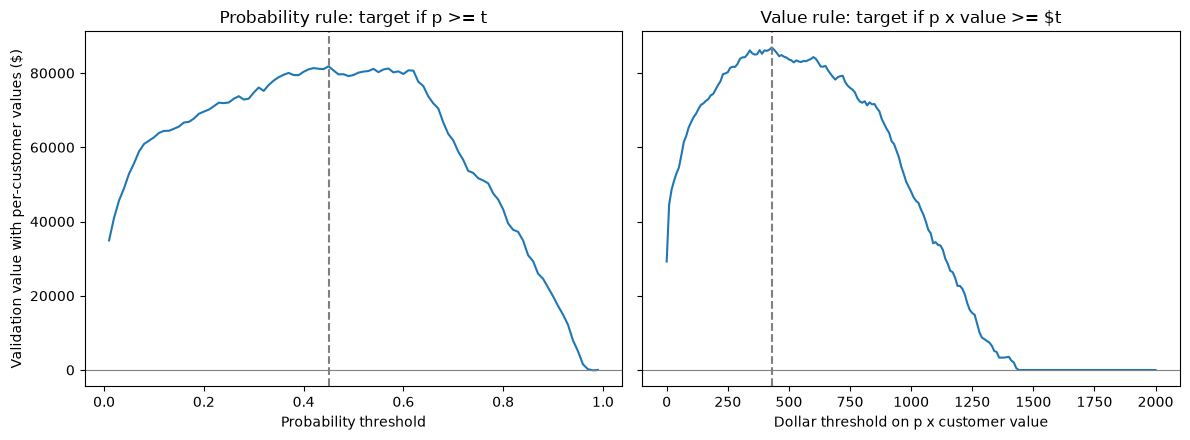

In [28]:
cfg = load_config()
econ, pcv = cfg["economics"], cfg["per_customer_value"]
cost, rate = econ["offer_cost"], econ["offer_success_rate"]
choice = json.loads((DOCS / "threshold.json").read_text())
model = choice["chosen_model"]

val = load_split("val")
preds = pd.read_csv(PROCESSED / "val_predictions.csv")
y = preds["y"].to_numpy()
assert (y == val["Churn"].to_numpy()).all(), "validation predictions out of order"
p = preds[model].to_numpy()

rows = []
for months in pcv["value_months_grid"]:
    v = customer_values(val["MonthlyCharges"], months)
    r = best_rule(y, p, v, cost, rate)
    perfect = realised_value(y, y == 1, v, cost, rate)
    rows.append(
        {
            "value_months": months,
            "mean_value": v.mean(),
            "prob_threshold": r["probability"]["threshold"],
            "prob_ev": r["probability"]["ev"],
            "prob_targeted": r["probability"]["targeted"],
            "value_threshold_$": r["value"]["threshold"],
            "value_ev": r["value"]["ev"],
            "value_targeted": r["value"]["targeted"],
            "value_minus_prob": r["value"]["ev"] - r["probability"]["ev"],
            "perfect_ev": perfect,
        }
    )
sens = pd.DataFrame(rows)

months = pcv["value_months"]
v = customer_values(val["MonthlyCharges"], months)
base = best_rule(y, p, v, cost, rate)

# Bootstrap the gap between the two rules (thresholds held fixed).
rng = np.random.default_rng(cfg["seed"])
tp, tv = base["probability"]["threshold"], base["value"]["threshold"]
gaps = []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    gaps.append(
        realised_value(y[i], p[i] * v[i] >= tv, v[i], cost, rate) - realised_value(y[i], p[i] >= tp, v[i], cost, rate)
    )
gaps = np.array(gaps)

# Who does each rule target? Compare monthly charges of targeted customers.
t_prob, t_val = p >= tp, p * v >= tv
profile = pd.DataFrame(
    {
        "probability rule": [t_prob.sum(), val.loc[t_prob, "MonthlyCharges"].median(), y[t_prob].mean()],
        "value rule": [t_val.sum(), val.loc[t_val, "MonthlyCharges"].median(), y[t_val].mean()],
    },
    index=["customers targeted", "median MonthlyCharges", "churn rate among targeted"],
)

out = {
    "model": model,
    "value_months": months,
    "offer_cost": cost,
    "offer_success_rate": rate,
    "probability_threshold": tp,
    "value_threshold_dollars": tv,
    "val_ev_probability_rule": base["probability"]["ev"],
    "val_ev_value_rule": base["value"]["ev"],
    "chosen_rule": "value" if base["value"]["ev"] > base["probability"]["ev"] else "probability",
    "bootstrap_gap_mean": float(gaps.mean()),
    "bootstrap_gap_ci95": [float(np.percentile(gaps, 2.5)), float(np.percentile(gaps, 97.5))],
    "bootstrap_share_value_better": float((gaps > 0).mean()),
}
(DOCS / "value_threshold.json").write_text(json.dumps(out, indent=2))

md = [
    "# Per-customer value targeting (validation set)",
    "",
    f"Model `{model}`. A lost customer is worth MonthlyCharges x {months} months "
    f"(validation mean ${v.mean():,.0f}, range ${v.min():,.0f}-${v.max():,.0f}). "
    f"Offer cost ${cost}, success rate {rate:.0%} (config/config.yaml).",
    "",
    "## Base case",
    "",
    "| Rule | Threshold | Customers targeted | Validation value |",
    "| --- | --- | ---: | ---: |",
    f"| Probability: p >= t | {tp:.2f} | {base['probability']['targeted']} | ${base['probability']['ev']:,.0f} |",
    f"| Value: p x value >= $t | ${tv:,.0f} | {base['value']['targeted']} | ${base['value']['ev']:,.0f} |",
    "",
    f"Chosen for test: **{out['chosen_rule']} rule**. Bootstrap (1,000 resamples) of value rule minus "
    f"probability rule: mean ${gaps.mean():,.0f}, 95% interval ${out['bootstrap_gap_ci95'][0]:,.0f} to "
    f"${out['bootstrap_gap_ci95'][1]:,.0f}; value rule better in {(gaps > 0).mean():.0%} of resamples.",
    "",
    "## Who gets targeted",
    "",
    profile.to_markdown(floatfmt=".2f"),
    "",
    "## Sensitivity to value_months",
    "",
    sens.to_markdown(index=False, floatfmt=".2f"),
    "",
]
show("\n".join(md))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
axes[0].plot(THRESHOLDS, base["probability"]["curve"])
axes[0].axvline(tp, color="grey", linestyle="--")
axes[0].set_xlabel("Probability threshold")
axes[0].set_title("Probability rule: target if p >= t")
axes[1].plot(DOLLAR_THRESHOLDS, base["value"]["curve"])
axes[1].axvline(tv, color="grey", linestyle="--")
axes[1].set_xlabel("Dollar threshold on p x customer value")
axes[1].set_title("Value rule: target if p x value >= $t")
axes[0].set_ylabel("Validation value with per-customer values ($)")
for ax in axes:
    ax.axhline(0, color="grey", linewidth=0.8)
fig.tight_layout()
fig.savefig(IMG / "value_policy.png", dpi=120)

## Part 4 · Final test evaluation and fairness check

**Input:** the model and threshold fixed in Part 3, and the test split. 

This is the **only** place the test split is loaded, and it is scored once. Nothing here feeds back into the
model or threshold choice.

### Part 1: score the test set once

In [29]:
def save_test_predictions(test, y: np.ndarray, p: np.ndarray, t: float) -> None:
    """Keep the final test scores (plus group columns) for the fairness report.

    Written once, after the model and threshold are fixed; the fairness section only
    reads this file, so nothing else needs to load the test split.
    """
    out = test[["customerID", "SeniorCitizen", "gender", "Contract", "tenure", "MonthlyCharges"]].copy()
    out["y"], out["p"], out["targeted"] = y, p, (p >= t).astype(int)
    out.to_csv(PROCESSED / "test_predictions.csv", index=False)

In [30]:
def value_rule_on_test(test, y: np.ndarray, p: np.ndarray) -> list[str]:
    """Score the per-customer value rules (chosen on validation) once on test."""
    path = DOCS / "value_threshold.json"
    if not path.exists():
        return []
    c = json.loads(path.read_text())
    v = customer_values(test["MonthlyCharges"], c["value_months"])
    cost, rate = c["offer_cost"], c["offer_success_rate"]
    prob = realised_value(y, p >= c["probability_threshold"], v, cost, rate)
    val = realised_value(y, p * v >= c["value_threshold_dollars"], v, cost, rate)
    perfect = realised_value(y, y == 1, v, cost, rate)
    res = {
        "probability_rule": prob,
        "value_rule": val,
        "perfect": perfect,
        "chosen_rule": c["chosen_rule"],
        "targeted_probability_rule": int((p >= c["probability_threshold"]).sum()),
        "targeted_value_rule": int((p * v >= c["value_threshold_dollars"]).sum()),
    }
    (DOCS / "test_value_results.json").write_text(json.dumps(res, indent=2))
    return [
        f"## Per-customer value (value = MonthlyCharges x {c['value_months']} months; rules chosen on validation)",
        "",
        f"- Probability rule, p >= {c['probability_threshold']:.2f}: **${prob:,.0f}** "
        f"({res['targeted_probability_rule']} targeted)",
        f"- Value rule, p x value >= ${c['value_threshold_dollars']:,.0f}: **${val:,.0f}** "
        f"({res['targeted_value_rule']} targeted)",
        f"- Perfect model: ${perfect:,.0f}",
        f"- Rule chosen on validation: {c['chosen_rule']}",
        "",
    ]

#### Score and report

In [31]:
choice = json.loads((DOCS / "threshold.json").read_text())
econ, t, name = choice["economics"], choice["threshold"], choice["chosen_model"]
model = joblib.load(MODELS_DIR / f"{name}.joblib")
X_te, y_te = xy(load_split("test"))
y = y_te.to_numpy()
p = model.predict_proba(X_te)[:, 1]

at_t = evaluate(y, p, t)
at_05 = evaluate(y, p, 0.5)
tn, fp, fn, tp = confusion_matrix(y, (p >= t).astype(int)).ravel()
args = (econ["offer_cost"], econ["customer_value"], econ["offer_success_rate"])
ev_t = expected_value(y, p, t, *args)
ev_05 = expected_value(y, p, 0.5, *args)
ev_all = expected_value(y, np.ones_like(p), 0.5, *args)
ev_perfect = int(y.sum()) * (econ["offer_success_rate"] * econ["customer_value"] - econ["offer_cost"])

res = {
    "model": name,
    "threshold": t,
    "test_rows": int(len(y)),
    "test_churn_rate": float(y.mean()),
    "metrics_at_threshold": at_t,
    "metrics_at_0.5": at_05,
    "confusion_at_threshold": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "ev_at_threshold": ev_t,
    "ev_at_0.5": ev_05,
    "ev_target_everyone": ev_all,
    "ev_perfect": ev_perfect,
}
(DOCS / "test_results.json").write_text(json.dumps(res, indent=2))


def row(label: str, m: dict) -> str:
    return (
        f"| {label} | {m['precision']:.4f} | {m['recall']:.4f} | {m['f1']:.4f} | "
        f"{m['pr_auc']:.4f} | {m['roc_auc']:.4f} | {m['brier']:.4f} |"
    )


md = [
    "# Final test-set evaluation (run once)",
    "",
    f"Model `{name}`, threshold {t:.2f} (both chosen on validation). Test rows: {len(y):,}, churn rate {y.mean():.4f}.",
    "",
    "| Threshold | Precision | Recall | F1 | PR-AUC | ROC-AUC | Brier |",
    "| --- | --- | --- | --- | --- | --- | --- |",
    row(f"{t:.2f} (EV-chosen)", at_t),
    row("0.50 (default)", at_05),
    "",
    f"Confusion matrix at {t:.2f}: TP {tp}, FP {fp}, FN {fn}, TN {tn}. Customers targeted: {tp + fp} of {len(y)}.",
    "",
    "## Expected value on test (same assumptions as config)",
    "",
    f"- EV-chosen threshold {t:.2f}: **${ev_t:,.0f}**",
    f"- Default threshold 0.50: ${ev_05:,.0f}",
    f"- Target everyone: ${ev_all:,.0f}",
    f"- Perfect model: ${ev_perfect:,.0f}",
    f"- Share of perfect-model value captured: {ev_t / ev_perfect:.1%}",
    "",
    "These dollar figures depend entirely on the assumed costs and are offline estimates, not measured savings.",
    "",
]
md += value_rule_on_test(load_split("test"), y, p)
save_test_predictions(load_split("test"), y, p, t)
show("\n".join(md))

# Final test-set evaluation (run once)

Model `random_forest`, threshold 0.45 (both chosen on validation). Test rows: 1,409, churn rate 0.2654.

| Threshold | Precision | Recall | F1 | PR-AUC | ROC-AUC | Brier |
| --- | --- | --- | --- | --- | --- | --- |
| 0.45 (EV-chosen) | 0.5024 | 0.8262 | 0.6249 | 0.6471 | 0.8445 | 0.1610 |
| 0.50 (default) | 0.5237 | 0.7968 | 0.6320 | 0.6471 | 0.8445 | 0.1610 |

Confusion matrix at 0.45: TP 309, FP 306, FN 65, TN 729. Customers targeted: 615 of 1409.

## Expected value on test (same assumptions as config)

- EV-chosen threshold 0.45: **$62,100**
- Default threshold 0.50: $62,300
- Target everyone: $8,700
- Perfect model: $112,200
- Share of perfect-model value captured: 55.3%

These dollar figures depend entirely on the assumed costs and are offline estimates, not measured savings.

## Per-customer value (value = MonthlyCharges x 15 months; rules chosen on validation)

- Probability rule, p >= 0.45: **$76,180** (615 targeted)
- Value rule, p x value >= $430: **$79,837** (605 targeted)
- Perfect model: $125,889
- Rule chosen on validation: value


---
## Part 2: fairness

Compare error rates across groups on the test set and show the report.

Groups: SeniorCitizen, gender and Contract. For each group we report precision,
recall, false-negative rate (churners the model misses) and selection rate
(share targeted), at the threshold chosen on validation. Gaps between groups
come with 95% bootstrap intervals, because some groups are small.

Reads data/processed/test_predictions.csv written in Part 1; nothing here changes the model or threshold.

In [32]:
GROUPS = ["SeniorCitizen", "gender", "Contract"]

In [33]:
def group_metrics(df: pd.DataFrame) -> dict[str, float]:
    """Precision, recall, FNR and selection rate for one group."""
    tp = int(((df["targeted"] == 1) & (df["y"] == 1)).sum())
    fp = int(((df["targeted"] == 1) & (df["y"] == 0)).sum())
    fn = int(((df["targeted"] == 0) & (df["y"] == 1)).sum())
    churners = tp + fn
    return {
        "customers": len(df),
        "churners": churners,
        "churn_rate": df["y"].mean(),
        "selection_rate": df["targeted"].mean(),
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "recall": tp / churners if churners else np.nan,
        "fnr": fn / churners if churners else np.nan,
    }

In [34]:
def table(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """Metrics for every level of one grouping column."""
    return pd.DataFrame({level: group_metrics(g) for level, g in df.groupby(col)}).T

In [35]:
def gap_ci(df: pd.DataFrame, col: str, metric: str, seed: int, n_boot: int = 1000) -> dict:
    """Largest-minus-smallest gap in a metric across levels, with a bootstrap 95% interval.

    Resamples customers within each level, so group sizes stay fixed.
    """
    rng = np.random.default_rng(seed)
    levels = {k: g for k, g in df.groupby(col)}
    point = table(df, col)[metric].astype(float)
    hi, lo = point.idxmax(), point.idxmin()
    diffs = []
    for _ in range(n_boot):
        a = levels[hi].iloc[rng.integers(0, len(levels[hi]), len(levels[hi]))]
        b = levels[lo].iloc[rng.integers(0, len(levels[lo]), len(levels[lo]))]
        diffs.append(group_metrics(a)[metric] - group_metrics(b)[metric])
    diffs = np.array(diffs, dtype=float)
    return {
        "metric": metric,
        "highest": str(hi),
        "lowest": str(lo),
        "gap": float(point[hi] - point[lo]),
        "ci_low": float(np.nanpercentile(diffs, 2.5)),
        "ci_high": float(np.nanpercentile(diffs, 97.5)),
    }

In [36]:
def interpret(out: dict) -> list[str]:
    """Plain-language reading built from the computed tables (no hand-typed numbers)."""
    sen, gen, con = out["SeniorCitizen"], out["gender"], out["Contract"]
    st, ct = sen["table"], con["table"]
    gen_sig = [g["metric"] for g in gen["gaps"] if g["ci_low"] > 0 or g["ci_high"] < 0]
    fnr_gap = next(g for g in sen["gaps"] if g["metric"] == "fnr")
    return [
        "",
        "## Reading the results",
        "",
        "**Gender:** "
        + (
            "no gap is distinguishable from noise; every 95% interval includes zero."
            if not gen_sig
            else f"intervals exclude zero for: {', '.join(gen_sig)}."
        ),
        "",
        f"**Senior citizens** are flagged far more often ({st['Yes']['selection_rate']:.1%} vs "
        f"{st['No']['selection_rate']:.1%}). Part of that is real: they churn at {st['Yes']['churn_rate']:.1%} vs "
        f"{st['No']['churn_rate']:.1%}, and precision is higher for them too. The gap that matters is in the "
        f"other direction: **{st['No']['fnr']:.1%} of non-senior churners are missed vs {st['Yes']['fnr']:.1%} "
        f"of senior churners** (gap {fnr_gap['gap']:+.1%}, interval {fnr_gap['ci_low']:+.1%} to "
        f"{fnr_gap['ci_high']:+.1%}). Non-senior customers who are about to leave are less likely to get an "
        f"offer. Only {int(st['Yes']['customers'])} seniors are in the test set, so the exact size is uncertain.",
        "",
        f"**Contract type** shows by far the largest gap: recall is {ct['Month-to-month']['recall']:.1%} for "
        f"month-to-month churners, {ct['One year']['recall']:.1%} for one-year and "
        f"{ct['Two year']['recall']:.1%} for two-year ({int(ct['Two year']['churners'])} churners, none "
        "flagged). Contract is not a protected attribute, but it is the model's main blind spot: long-contract "
        "customers who leave almost never get an offer.",
        "",
        "## Options (not applied)",
        "",
        "- **Do nothing, but monitor.** The offer is a benefit, not a penalty, so a higher selection rate for "
        "seniors does not harm them. The cost is to non-senior churners who miss out. Track FNR by group "
        "after launch.",
        "- **Group-specific thresholds** could equalise FNR, but using age directly in a decision rule needs "
        f"legal and policy review, and with {int(st['Yes']['customers'])} seniors the thresholds would be noisy.",
        "- **Drop SeniorCitizen as a feature.** This removes direct use of age, but other features correlate "
        "with it, so gaps may persist; it would need re-validation.",
        "- **Separate process for long contracts.** A renewal-time check-in for one- and two-year customers "
        "addresses the contract gap better than any threshold change.",
        "",
        "Caveats: one test set of 1,409 customers; differences in base rates mean no single threshold can "
        "equalise every metric at once; and none of this says anything about *why* groups differ.",
        "",
    ]

#### Group tables and gaps

In [37]:
cfg = load_config()
df = pd.read_csv(PROCESSED / "test_predictions.csv")
choice = json.loads((DOCS / "threshold.json").read_text())

md = [
    "# Fairness check (test set)",
    "",
    f"Model `{choice['chosen_model']}` at threshold "
    f"{choice['threshold']:.2f}, both fixed on validation. {len(df):,} test customers. "
    "Gaps are highest group minus lowest group, with 95% bootstrap intervals (1,000 resamples within groups).",
    "",
    "- **Recall**: share of a group's churners the model flags. **FNR** = 1 - recall: churners it misses, "
    "who never get an offer.",
    "- **Precision**: share of flagged customers who really churn. **Selection rate**: share of the group "
    "that gets an offer.",
]
out: dict = {}
for col in GROUPS:
    t = table(df, col)
    gaps = [gap_ci(df, col, m, cfg["seed"]) for m in ("recall", "fnr", "precision", "selection_rate")]
    out[col] = {"table": t.astype(float).to_dict(orient="index"), "gaps": gaps}
    shown = t.copy()
    for c in ("churn_rate", "selection_rate", "precision", "recall", "fnr"):
        shown[c] = shown[c].astype(float).map(lambda v: "n/a" if np.isnan(v) else f"{v:.1%}")
    md += [
        "",
        f"## {col}",
        "",
        shown.to_markdown(),
        "",
        "| Gap | Highest | Lowest | Gap | 95% interval |",
        "| --- | --- | --- | ---: | --- |",
    ]
    md += [
        f"| {g['metric']} | {g['highest']} | {g['lowest']} | {g['gap']:+.1%} | "
        f"{g['ci_low']:+.1%} to {g['ci_high']:+.1%} |"
        for g in gaps
    ]
(DOCS / "fairness.json").write_text(json.dumps(out, indent=2, default=float))
md += interpret(out)
show("\n".join(md))

# Fairness check (test set)

Model `random_forest` at threshold 0.45, both fixed on validation. 1,409 test customers. Gaps are highest group minus lowest group, with 95% bootstrap intervals (1,000 resamples within groups).

- **Recall**: share of a group's churners the model flags. **FNR** = 1 - recall: churners it misses, who never get an offer.
- **Precision**: share of flagged customers who really churn. **Selection rate**: share of the group that gets an offer.

## SeniorCitizen

|     |   customers |   churners | churn_rate   | selection_rate   | precision   | recall   | fnr   |
|:----|------------:|-----------:|:-------------|:-----------------|:------------|:---------|:------|
| No  |        1187 |        276 | 23.3%        | 39.0%            | 47.1%       | 79.0%    | 21.0% |
| Yes |         222 |         98 | 44.1%        | 68.5%            | 59.9%       | 92.9%    | 7.1%  |

| Gap | Highest | Lowest | Gap | 95% interval |
| --- | --- | --- | ---: | --- |
| recall | Yes | No | +13.9% | +6.8% to +20.8% |
| fnr | No | Yes | +13.9% | +6.4% to +20.4% |
| precision | Yes | No | +12.8% | +4.5% to +21.0% |
| selection_rate | Yes | No | +29.5% | +22.7% to +36.3% |

## gender

|        |   customers |   churners | churn_rate   | selection_rate   | precision   | recall   | fnr   |
|:-------|------------:|-----------:|:-------------|:-----------------|:------------|:---------|:------|
| Female |         687 |        193 | 28.1%        | 43.2%            | 52.9%       | 81.3%    | 18.7% |
| Male   |         722 |        181 | 25.1%        | 44.0%            | 47.8%       | 84.0%    | 16.0% |

| Gap | Highest | Lowest | Gap | 95% interval |
| --- | --- | --- | ---: | --- |
| recall | Male | Female | +2.6% | -4.5% to +10.2% |
| fnr | Female | Male | +2.6% | -5.5% to +9.7% |
| precision | Female | Male | +5.1% | -3.2% to +12.5% |
| selection_rate | Male | Female | +0.8% | -4.2% to +5.8% |

## Contract

|                |   customers |   churners | churn_rate   | selection_rate   | precision   | recall   | fnr    |
|:---------------|------------:|-----------:|:-------------|:-----------------|:------------|:---------|:-------|
| Month-to-month |         773 |        329 | 42.6%        | 76.1%            | 51.4%       | 91.8%    | 8.2%   |
| One year       |         300 |         36 | 12.0%        | 9.0%             | 25.9%       | 19.4%    | 80.6%  |
| Two year       |         336 |          9 | 2.7%         | 0.0%             | n/a         | 0.0%     | 100.0% |

| Gap | Highest | Lowest | Gap | 95% interval |
| --- | --- | --- | ---: | --- |
| recall | Month-to-month | Two year | +91.8% | +89.0% to +94.6% |
| fnr | Two year | Month-to-month | +91.8% | +88.9% to +94.5% |
| precision | Month-to-month | One year | +25.4% | +7.7% to +40.2% |
| selection_rate | Month-to-month | Two year | +76.1% | +73.0% to +79.0% |

## Reading the results

**Gender:** no gap is distinguishable from noise; every 95% interval includes zero.

**Senior citizens** are flagged far more often (68.5% vs 39.0%). Part of that is real: they churn at 44.1% vs 23.3%, and precision is higher for them too. The gap that matters is in the other direction: **21.0% of non-senior churners are missed vs 7.1% of senior churners** (gap +13.9%, interval +6.4% to +20.4%). Non-senior customers who are about to leave are less likely to get an offer. Only 222 seniors are in the test set, so the exact size is uncertain.

**Contract type** shows by far the largest gap: recall is 91.8% for month-to-month churners, 19.4% for one-year and 0.0% for two-year (9 churners, none flagged). Contract is not a protected attribute, but it is the model's main blind spot: long-contract customers who leave almost never get an offer.

## Options (not applied)

- **Do nothing, but monitor.** The offer is a benefit, not a penalty, so a higher selection rate for seniors does not harm them. The cost is to non-senior churners who miss out. Track FNR by group after launch.
- **Group-specific thresholds** could equalise FNR, but using age directly in a decision rule needs legal and policy review, and with 222 seniors the thresholds would be noisy.
- **Drop SeniorCitizen as a feature.** This removes direct use of age, but other features correlate with it, so gaps may persist; it would need re-validation.
- **Separate process for long contracts.** A renewal-time check-in for one- and two-year customers addresses the contract gap better than any threshold change.

Caveats: one test set of 1,409 customers; differences in base rates mean no single threshold can equalise every metric at once; and none of this says anything about *why* groups differ.


## Part 5 · SHAP explanations and error analysis

**Input:** the chosen model and the validation split. 

SHAP explains what the **model** relies on. It does not show what causes customers to churn.

### Notes

SHAP is computed on the uncalibrated pipeline of the chosen model family.
Sigmoid calibration is a monotone rescaling of each fold model's score, so it
changes probability values but not which features push a prediction up or down.

In [38]:
def error_analysis(val: pd.DataFrame, p: np.ndarray, t: float) -> list[str]:
    """Compare churners the model catches with those it misses."""
    df = val.copy()
    df["p"] = p
    churners = df[df["Churn"] == 1].copy()
    churners["outcome"] = np.where(churners["p"] >= t, "caught (TP)", "missed (FN)")
    nonchurn = df[df["Churn"] == 0]
    fp = nonchurn[nonchurn["p"] >= t]

    lines = [
        "# Error analysis (validation set)",
        "",
        f"Threshold {t:.2f}. Churners: {len(churners)}; caught {int((churners['outcome'] == 'caught (TP)').sum())}, "
        f"missed {int((churners['outcome'] == 'missed (FN)').sum())}. "
        f"False positives (targeted but stayed): {len(fp)} of {len(nonchurn)} non-churners.",
        "",
    ]

    num = churners.groupby("outcome")[["tenure", "MonthlyCharges", "TotalCharges", "p"]].median().round(2)
    lines += ["## Median profile of churners, caught vs missed", "", num.to_markdown(), ""]

    for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity"]:
        tab = pd.crosstab(churners[col], churners["outcome"])
        tab["miss_rate"] = (tab.get("missed (FN)", 0) / tab.sum(axis=1)).round(3)
        lines += [f"## Missed share of churners by {col}", "", tab.to_markdown(), ""]

    churners["tenure_band"] = pd.cut(
        churners["tenure"], [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"]
    )
    tab = pd.crosstab(churners["tenure_band"], churners["outcome"])
    tab["miss_rate"] = (tab.get("missed (FN)", 0) / tab.sum(axis=1)).round(3)
    lines += ["## Missed share of churners by tenure (months)", "", tab.to_markdown(), ""]

    fp_profile = pd.DataFrame(
        {
            "false_positives": fp[["tenure", "MonthlyCharges"]].median(),
            "all_non_churners": nonchurn[["tenure", "MonthlyCharges"]].median(),
        }
    ).round(2)
    lines += [
        "## Median profile of false positives vs all non-churners",
        "",
        fp_profile.to_markdown(),
        "",
        f"Month-to-month share: false positives {(fp['Contract'] == 'Month-to-month').mean():.1%}, "
        f"all non-churners {(nonchurn['Contract'] == 'Month-to-month').mean():.1%}.",
        "",
    ]
    return lines

#### SHAP on validation

SHAP on random_forest (validation). Top features:
Contract_Month-to-month           0.1359
OnlineSecurity_No                 0.0520
tenure                            0.0508
InternetService_Fiber optic       0.0491
MonthlyCharges                    0.0391
Contract_Two year                 0.0359
TotalCharges                      0.0299
TechSupport_No                    0.0224
PaymentMethod_Electronic check    0.0142
InternetService_DSL               0.0097


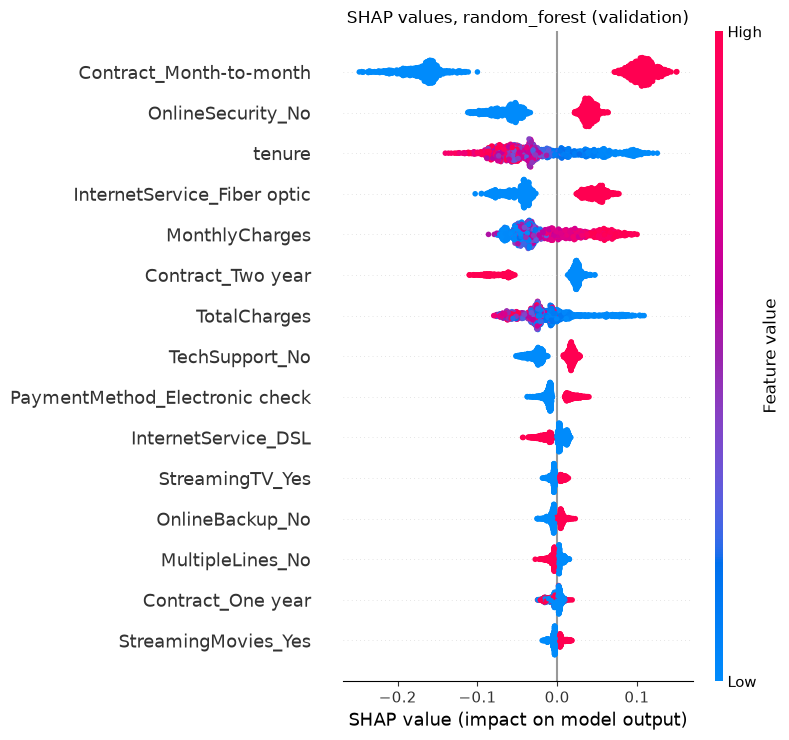

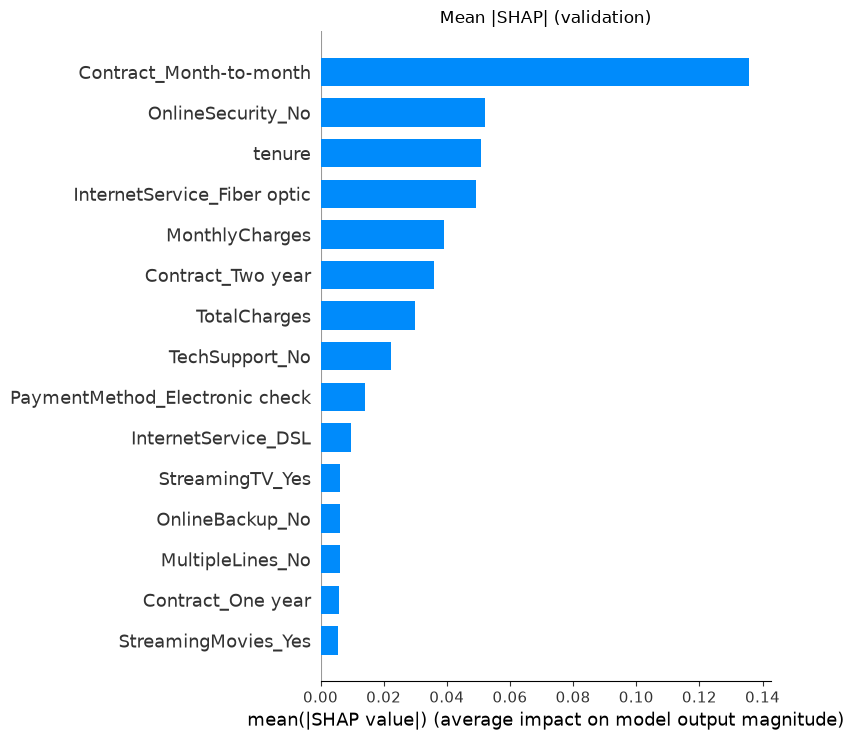

In [39]:
cfg = load_config()
choice = json.loads((DOCS / "threshold.json").read_text())
name, t = choice["chosen_model"], choice["threshold"]
family = name.removesuffix("_calibrated")
pipe = joblib.load(MODELS_DIR / f"{family}.joblib")
chosen = joblib.load(MODELS_DIR / f"{name}.joblib")

train, val = load_split("train"), load_split("val")
X_tr, _ = xy(train)
X_va, _ = xy(val)
background = X_tr.sample(200, random_state=cfg["seed"])
sv, Xt = shap_values_for(pipe, X_va, background, cfg["seed"])

imp = pd.Series(np.abs(sv).mean(axis=0), index=Xt.columns).sort_values(ascending=False)
imp.rename("mean_abs_shap").to_csv(DOCS / "shap_importance.csv")
print(f"SHAP on {family} (validation). Top features:\n{imp.head(10).round(4).to_string()}")

# shap seeds numpy's global RNG for the beeswarm jitter and warns about it; the warning is expected.
warnings.filterwarnings("ignore", message="The NumPy global RNG", category=FutureWarning)
np.random.seed(cfg["seed"])  # beeswarm jitter uses the global RNG
plt.figure()
shap.summary_plot(sv, Xt, max_display=15, show=False)
plt.title(f"SHAP values, {family} (validation)")
plt.tight_layout()
plt.savefig(IMG / "shap_summary.png", dpi=120, bbox_inches="tight")

plt.figure()
shap.summary_plot(sv, Xt, plot_type="bar", max_display=15, show=False)
plt.title("Mean |SHAP| (validation)")
plt.tight_layout()
plt.savefig(IMG / "shap_bar.png", dpi=120, bbox_inches="tight")

#### Error analysis: who does the model miss?

In [40]:
p = chosen.predict_proba(X_va)[:, 1]
lines = error_analysis(val, p, t)
show("\n".join(lines))

# Error analysis (validation set)

Threshold 0.45. Churners: 374; caught 313, missed 61. False positives (targeted but stayed): 320 of 1035 non-churners.

## Median profile of churners, caught vs missed

| outcome     |   tenure |   MonthlyCharges |   TotalCharges |    p |
|:------------|---------:|-----------------:|---------------:|-----:|
| caught (TP) |        8 |            82.85 |         662.65 | 0.74 |
| missed (FN) |       49 |            62.3  |        2791.5  | 0.28 |

## Missed share of churners by Contract

| Contract       |   caught (TP) |   missed (FN) |   miss_rate |
|:---------------|--------------:|--------------:|------------:|
| Month-to-month |           304 |            20 |       0.062 |
| One year       |             9 |            28 |       0.757 |
| Two year       |             0 |            13 |       1     |

## Missed share of churners by InternetService

| InternetService   |   caught (TP) |   missed (FN) |   miss_rate |
|:------------------|--------------:|--------------:|------------:|
| DSL               |            61 |            26 |       0.299 |
| Fiber optic       |           242 |            23 |       0.087 |
| No                |            10 |            12 |       0.545 |

## Missed share of churners by PaymentMethod

| PaymentMethod             |   caught (TP) |   missed (FN) |   miss_rate |
|:--------------------------|--------------:|--------------:|------------:|
| Bank transfer (automatic) |            31 |            20 |       0.392 |
| Credit card (automatic)   |            30 |            14 |       0.318 |
| Electronic check          |           205 |            17 |       0.077 |
| Mailed check              |            47 |            10 |       0.175 |

## Missed share of churners by TechSupport

| TechSupport         |   caught (TP) |   missed (FN) |   miss_rate |
|:--------------------|--------------:|--------------:|------------:|
| No                  |           263 |            24 |       0.084 |
| No internet service |            10 |            12 |       0.545 |
| Yes                 |            40 |            25 |       0.385 |

## Missed share of churners by OnlineSecurity

| OnlineSecurity      |   caught (TP) |   missed (FN) |   miss_rate |
|:--------------------|--------------:|--------------:|------------:|
| No                  |           260 |            29 |       0.1   |
| No internet service |            10 |            12 |       0.545 |
| Yes                 |            43 |            20 |       0.317 |

## Missed share of churners by tenure (months)

| tenure_band   |   caught (TP) |   missed (FN) |   miss_rate |
|:--------------|--------------:|--------------:|------------:|
| 0-6           |           135 |             3 |       0.022 |
| 7-12          |            55 |             6 |       0.098 |
| 13-24         |            42 |             8 |       0.16  |
| 25-48         |            62 |            13 |       0.173 |
| 49-72         |            19 |            31 |       0.62  |

## Median profile of false positives vs all non-churners

|                |   false_positives |   all_non_churners |
|:---------------|------------------:|-------------------:|
| tenure         |             19    |              39    |
| MonthlyCharges |             80.45 |              64.55 |

Month-to-month share: false positives 93.4%, all non-churners 43.7%.


## Part 6 · Survival analysis

**Input:** training split. 

The classifier answers *will this customer churn?* Survival analysis answers *how long do customers stay, and
what changes the rate of leaving over time?* Duration = tenure (months), event = churn. Customers who haven't
churned are right-censored: we only know they stayed at least `tenure` months.

### Helper functions

Training split only (the same rows the classifier learns from).

In [41]:
# Covariates for the Cox model. Contract is left out of the main model and used as
# a stratum instead if it breaks proportional hazards (checked below).
COX_CATEGORICAL = [
    "InternetService",
    "PaymentMethod",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "OnlineSecurity",
    "TechSupport",
    "PaperlessBilling",
    "Contract",
]
COX_NUMERIC = ["MonthlyCharges"]

In [42]:
def km_plot(df: pd.DataFrame, by: str, path) -> pd.DataFrame:
    """Kaplan-Meier curves for each level of `by`; returns survival at 12/24/48/72 months."""
    fig, ax = plt.subplots(figsize=(8, 5))
    rows = {}
    for level, g in df.groupby(by):
        km = KaplanMeierFitter().fit(g["tenure"], g["Churn"], label=f"{level} (n={len(g)})")
        km.plot_survival_function(ax=ax, ci_show=True)
        rows[level] = {f"S({m})": float(km.survival_function_at_times(m).iloc[0]) for m in (12, 24, 48, 72)}
        rows[level]["median_months"] = km.median_survival_time_
    ax.set_xlabel("Tenure (months)")
    ax.set_ylabel("Share still a customer")
    ax.set_title(f"Kaplan-Meier: staying probability by {by} (training split)")
    ax.set_ylim(0, 1.02)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    return pd.DataFrame(rows).T

In [43]:
def design(df: pd.DataFrame, categorical: list[str]) -> pd.DataFrame:
    """One-hot covariates (first level dropped) plus duration and event columns."""
    x = pd.get_dummies(df[categorical], drop_first=True, dtype=float)
    x.columns = [c.replace(" ", "_").replace("(", "").replace(")", "") for c in x.columns]
    # "No internet service" in TechSupport/OnlineSecurity duplicates InternetService_No exactly.
    x = x.drop(columns=[c for c in x.columns if c.endswith("_No_internet_service")])
    x["MonthlyCharges_per_10"] = df["MonthlyCharges"] / 10
    x["tenure"] = df["tenure"].clip(lower=0.5)  # tenure 0 -> half a month so durations are positive
    x["Churn"] = df["Churn"]
    return x

In [44]:
def fit_cox(x: pd.DataFrame, strata: list[str] | None = None) -> CoxPHFitter:
    """Penalised Cox model (small L2 for numerical stability)."""
    cph = CoxPHFitter(penalizer=0.01)
    cph.fit(x, duration_col="tenure", event_col="Churn", strata=strata)
    return cph

In [45]:
def ph_check(cph: CoxPHFitter, x: pd.DataFrame) -> pd.DataFrame:
    """Schoenfeld-residual test of the proportional hazards assumption per covariate."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = proportional_hazard_test(cph, x, time_transform="rank")
    return res.summary[["test_statistic", "p"]].sort_values("p")

#### Kaplan-Meier curves and log-rank test

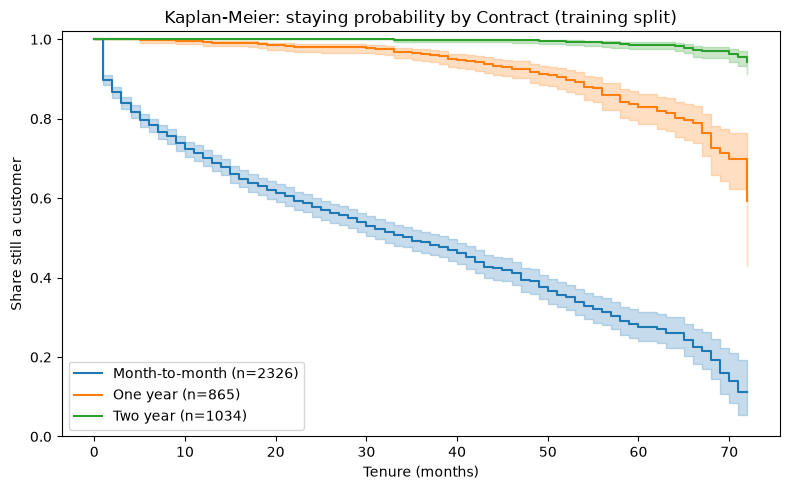

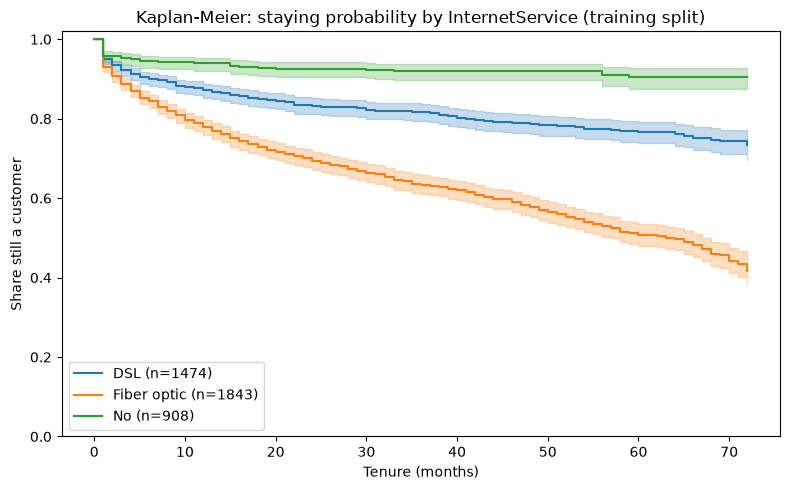

In [46]:
train = load_split("train")
km_contract = km_plot(train, "Contract", IMG / "km_contract.png")
km_internet = km_plot(train, "InternetService", IMG / "km_internet.png")
logrank = multivariate_logrank_test(train["tenure"], train["Contract"], train["Churn"])

#### Cox model, proportional-hazards check, then stratify on Contract

In [47]:
# 1) Cox with Contract as a covariate, then test proportional hazards.
x_full = design(train, COX_CATEGORICAL)
cox_full = fit_cox(x_full)
ph_full = ph_check(cox_full, x_full)
contract_terms = [c for c in ph_full.index if c.startswith("Contract")]
contract_violates = bool((ph_full.loc[contract_terms, "p"] < 0.05).any())

# 2) If Contract violates PH, stratify on it: each contract type gets its own baseline hazard.
cats_no_contract = [c for c in COX_CATEGORICAL if c != "Contract"]
x_strat = design(train, cats_no_contract)
x_strat["Contract"] = train["Contract"].to_numpy()
cox_strat = fit_cox(x_strat, strata=["Contract"])
ph_strat = ph_check(cox_strat, x_strat)
still_violating = ph_strat[ph_strat["p"] < 0.05]

hr = cox_strat.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].rename(
    columns={"exp(coef)": "hazard_ratio", "exp(coef) lower 95%": "ci_low", "exp(coef) upper 95%": "ci_high"}
)
hr = hr.sort_values("hazard_ratio", ascending=False)
hr_full = cox_full.summary.loc[contract_terms, ["exp(coef)", "p"]].rename(columns={"exp(coef)": "hazard_ratio"})

#### The survival report

In [48]:
md = [
    "# Survival analysis (training split)",
    "",
    f"{len(train):,} training customers, "
    f"{int(train['Churn'].sum()):,} churned (events); the rest are censored at their current tenure.",
    "",
    "## Kaplan-Meier by contract",
    "",
    "Share still a customer at 12/24/48/72 months, and median tenure (inf = more than half are still "
    "customers at 72 months, the longest tenure observed):",
    "",
    km_contract.to_markdown(floatfmt=".3f"),
    "",
    f"Log-rank test across the three contract types: chi-squared {logrank.test_statistic:,.1f}, "
    + ("p < 1e-10." if logrank.p_value < 1e-10 else f"p = {logrank.p_value:.2g}."),
    "",
    "## Kaplan-Meier by internet service",
    "",
    km_internet.to_markdown(floatfmt=".3f"),
    "",
    "## Cox proportional hazards",
    "",
    "A hazard ratio above 1 means a higher rate of leaving at any given tenure, holding the other "
    "covariates fixed. Monthly charges are per $10.",
    "",
    "### Checking the proportional hazards assumption",
    "",
    "Cox assumes each covariate multiplies the hazard by the same factor at every tenure. Tested with "
    "Schoenfeld residuals (rank time transform) on a first model that includes Contract as a covariate:",
    "",
    ph_full.to_markdown(floatfmt=".4g"),
    "",
    f"Contract terms {'**violate**' if contract_violates else 'do not violate'} the assumption "
    f"(p < 0.05). In that first model the contract hazard ratios were "
    + ", ".join(f"{k} {v:.2f}" for k, v in hr_full["hazard_ratio"].items())
    + ", but a single ratio is misleading when the effect changes with tenure.",
    "",
    "So the final model **stratifies on Contract**: each contract type gets its own baseline hazard "
    "(the KM curves above show how different they are) and the other covariates share one ratio. "
    "PH test on the stratified model:",
    "",
    ph_strat.to_markdown(floatfmt=".4g"),
    "",
    (
        f"{len(still_violating)} covariate(s) still have p < 0.05: "
        + ", ".join(still_violating.index)
        + ". Their hazard ratios are averages over tenure and should be "
        "read as rough summaries."
        if len(still_violating)
        else "No remaining covariate has p < 0.05."
    ),
    "",
    "### Hazard ratios (stratified by Contract)",
    "",
    hr.to_markdown(floatfmt=".3f"),
    "",
    f"Concordance (training): {cox_strat.concordance_index_:.3f}.",
    "",
    "## Reading it",
    "",
    f"- **Contract dominates.** After 12 months, {km_contract.loc['Month-to-month', 'S(12)']:.1%} of "
    f"month-to-month customers remain vs {km_contract.loc['One year', 'S(12)']:.1%} on one-year and "
    f"{km_contract.loc['Two year', 'S(12)']:.1%} on two-year contracts. Month-to-month customers have a median "
    f"tenure of {km_contract.loc['Month-to-month', 'median_months']:.0f} months; for the other two, more than "
    "half are still customers at 72 months. The one-year curve drops more after 48 months, plausibly around "
    "renewals.",
    f"- **Fiber optic** customers leave at {hr.loc['InternetService_Fiber_optic', 'hazard_ratio']:.2f}x the "
    "rate of DSL customers on the same contract and with the same bill; **electronic-check** and "
    "**mailed-check** payers at "
    f"{hr.loc['PaymentMethod_Electronic_check', 'hazard_ratio']:.2f}x and "
    f"{hr.loc['PaymentMethod_Mailed_check', 'hazard_ratio']:.2f}x bank-transfer payers.",
    f"- **Monthly charges** have a hazard ratio of {hr.loc['MonthlyCharges_per_10', 'hazard_ratio']:.2f} per "
    "$10 *after* adjusting for fiber and add-on services. That is not 'higher bills keep customers': "
    "fiber and the add-ons raise the bill, so once they are in the model the remaining charge effect is a "
    "conditional one, and it also fails the PH test. Treat it with care.",
    "- These are associations in observational data, like SHAP values. A hazard ratio is not the effect "
    "of switching a customer's contract or payment method.",
    "",
    "## What survival analysis adds beyond the classifier",
    "",
    "- **Timing, not just whether.** The classifier gives one churn probability per customer at a "
    "snapshot. The survival curves say *when* risk is concentrated: month-to-month customers lose "
    f"{1 - km_contract.loc['Month-to-month', 'S(12)']:.0%} in the first year, which argues for "
    "retention effort early in the relationship rather than evenly over time.",
    "- **Uses censored customers correctly.** A customer with 3 months of tenure who hasn't churned is "
    "not a 'non-churner'; they just haven't had time. The classifier labels them 0; survival analysis "
    "treats them as 'stayed at least 3 months', which is what we actually know.",
    "- **Expected remaining lifetime.** Survival curves give expected tenure, which is a better basis "
    "for the per-customer value used in Part 3 (bill x 15 months) than one fixed number "
    "of months. Not done here, but this is the natural next step.",
    "- **Limitation of this dataset:** it is one snapshot, so tenure mixes customers who joined at "
    "different times, and we can't see customers who churned before the snapshot window. The curves "
    "describe this sample, not a cohort followed over time.",
    "",
]
show("\n".join(md))

# Survival analysis (training split)

4,225 training customers, 1,121 churned (events); the rest are censored at their current tenure.

## Kaplan-Meier by contract

Share still a customer at 12/24/48/72 months, and median tenure (inf = more than half are still customers at 72 months, the longest tenure observed):

|                |   S(12) |   S(24) |   S(48) |   S(72) |   median_months |
|:---------------|--------:|--------:|--------:|--------:|----------------:|
| Month-to-month |   0.701 |   0.577 |   0.390 |   0.112 |          35.000 |
| One year       |   0.993 |   0.981 |   0.917 |   0.592 |         inf     |
| Two year       |   1.000 |   1.000 |   0.998 |   0.942 |         inf     |

Log-rank test across the three contract types: chi-squared 1,465.4, p < 1e-10.

## Kaplan-Meier by internet service

|             |   S(12) |   S(24) |   S(48) |   S(72) |   median_months |
|:------------|--------:|--------:|--------:|--------:|----------------:|
| DSL         |   0.871 |   0.832 |   0.787 |   0.734 |         inf     |
| Fiber optic |   0.779 |   0.694 |   0.579 |   0.417 |          63.000 |
| No          |   0.940 |   0.926 |   0.919 |   0.904 |         inf     |

## Cox proportional hazards

A hazard ratio above 1 means a higher rate of leaving at any given tenure, holding the other covariates fixed. Monthly charges are per $10.

### Checking the proportional hazards assumption

Cox assumes each covariate multiplies the hazard by the same factor at every tenure. Tested with Schoenfeld residuals (rank time transform) on a first model that includes Contract as a covariate:

|                                     |   test_statistic |         p |
|:------------------------------------|-----------------:|----------:|
| MonthlyCharges_per_10               |         22.29    | 2.339e-06 |
| Contract_One_year                   |         15.42    | 8.608e-05 |
| TechSupport_Yes                     |         10.18    | 0.001423  |
| OnlineSecurity_Yes                  |          5.027   | 0.02495   |
| PaymentMethod_Credit_card_automatic |          4.276   | 0.03865   |
| PaymentMethod_Mailed_check          |          3.646   | 0.0562    |
| InternetService_Fiber_optic         |          2.975   | 0.08457   |
| Partner_Yes                         |          2.848   | 0.09149   |
| PaymentMethod_Electronic_check      |          1.836   | 0.1754    |
| Dependents_Yes                      |          1.827   | 0.1764    |
| Contract_Two_year                   |          0.4431  | 0.5056    |
| SeniorCitizen_Yes                   |          0.2504  | 0.6168    |
| InternetService_No                  |          0.2392  | 0.6248    |
| PaperlessBilling_Yes                |          0.08798 | 0.7668    |

Contract terms **violate** the assumption (p < 0.05). In that first model the contract hazard ratios were Contract_One_year 0.21, Contract_Two_year 0.07, but a single ratio is misleading when the effect changes with tenure.

So the final model **stratifies on Contract**: each contract type gets its own baseline hazard (the KM curves above show how different they are) and the other covariates share one ratio. PH test on the stratified model:

|                                     |   test_statistic |         p |
|:------------------------------------|-----------------:|----------:|
| MonthlyCharges_per_10               |         26.06    | 3.309e-07 |
| TechSupport_Yes                     |         10.14    | 0.001453  |
| InternetService_Fiber_optic         |          6.279   | 0.01222   |
| OnlineSecurity_Yes                  |          4.526   | 0.03338   |
| PaymentMethod_Credit_card_automatic |          3.866   | 0.04926   |
| Partner_Yes                         |          2.83    | 0.09251   |
| PaymentMethod_Mailed_check          |          2.276   | 0.1314    |
| Dependents_Yes                      |          1.793   | 0.1806    |
| PaymentMethod_Electronic_check      |          1.692   | 0.1934    |
| SeniorCitizen_Yes                   |          0.07136 | 0.7894    |
| PaperlessBilling_Yes                |          0.06003 | 0.8064    |
| InternetService_No                  |          0.05506 | 0.8145    |

5 covariate(s) still have p < 0.05: MonthlyCharges_per_10, TechSupport_Yes, InternetService_Fiber_optic, OnlineSecurity_Yes, PaymentMethod_Credit_card_automatic. Their hazard ratios are averages over tenure and should be read as rough summaries.

### Hazard ratios (stratified by Contract)

| covariate                           |   hazard_ratio |   ci_low |   ci_high |     p |
|:------------------------------------|---------------:|---------:|----------:|------:|
| InternetService_Fiber_optic         |          2.140 |    1.702 |     2.692 | 0.000 |
| PaymentMethod_Mailed_check          |          1.924 |    1.561 |     2.373 | 0.000 |
| PaymentMethod_Electronic_check      |          1.736 |    1.470 |     2.049 | 0.000 |
| PaperlessBilling_Yes                |          1.183 |    1.028 |     1.360 | 0.019 |
| SeniorCitizen_Yes                   |          0.925 |    0.804 |     1.063 | 0.272 |
| PaymentMethod_Credit_card_automatic |          0.893 |    0.721 |     1.106 | 0.300 |
| Dependents_Yes                      |          0.889 |    0.751 |     1.053 | 0.172 |
| MonthlyCharges_per_10               |          0.861 |    0.821 |     0.902 | 0.000 |
| TechSupport_Yes                     |          0.706 |    0.600 |     0.830 | 0.000 |
| Partner_Yes                         |          0.607 |    0.531 |     0.695 | 0.000 |
| OnlineSecurity_Yes                  |          0.538 |    0.457 |     0.634 | 0.000 |
| InternetService_No                  |          0.383 |    0.289 |     0.506 | 0.000 |

Concordance (training): 0.710.

## Reading it

- **Contract dominates.** After 12 months, 70.1% of month-to-month customers remain vs 99.3% on one-year and 100.0% on two-year contracts. Month-to-month customers have a median tenure of 35 months; for the other two, more than half are still customers at 72 months. The one-year curve drops more after 48 months, plausibly around renewals.
- **Fiber optic** customers leave at 2.14x the rate of DSL customers on the same contract and with the same bill; **electronic-check** and **mailed-check** payers at 1.74x and 1.92x bank-transfer payers.
- **Monthly charges** have a hazard ratio of 0.86 per $10 *after* adjusting for fiber and add-on services. That is not 'higher bills keep customers': fiber and the add-ons raise the bill, so once they are in the model the remaining charge effect is a conditional one, and it also fails the PH test. Treat it with care.
- These are associations in observational data, like SHAP values. A hazard ratio is not the effect of switching a customer's contract or payment method.

## What survival analysis adds beyond the classifier

- **Timing, not just whether.** The classifier gives one churn probability per customer at a snapshot. The survival curves say *when* risk is concentrated: month-to-month customers lose 30% in the first year, which argues for retention effort early in the relationship rather than evenly over time.
- **Uses censored customers correctly.** A customer with 3 months of tenure who hasn't churned is not a 'non-churner'; they just haven't had time. The classifier labels them 0; survival analysis treats them as 'stayed at least 3 months', which is what we actually know.
- **Expected remaining lifetime.** Survival curves give expected tenure, which is a better basis for the per-customer value used in Part 3 (bill x 15 months) than one fixed number of months. Not done here, but this is the natural next step.
- **Limitation of this dataset:** it is one snapshot, so tenure mixes customers who joined at different times, and we can't see customers who churned before the snapshot window. The curves describe this sample, not a cohort followed over time.


## Part 7 · Model card



### Assemble the card

In [49]:
def load(name: str) -> dict:
    """Read one JSON result file from data/results/."""
    return json.loads((DOCS / name).read_text())

In [50]:
cfg = load_config()
th, te, fair = load("threshold.json"), load("test_results.json"), load("fairness.json")
val_rules = load("test_value_results.json") if (DOCS / "test_value_results.json").exists() else None
m, m05, cm = te["metrics_at_threshold"], te["metrics_at_0.5"], te["confusion_at_threshold"]
econ = th["economics"]


def gap_line(group: str) -> str:
    g = {x["metric"]: x for x in fair[group]["gaps"]}["fnr"]
    return (
        f"| {group} | {g['highest']} vs {g['lowest']} | {g['gap']:+.1%} | {g['ci_low']:+.1%} to {g['ci_high']:+.1%} |"
    )


val = pd.read_csv(DOCS / "results.csv")
pr_lo, pr_hi = val["pr_auc"].min(), val["pr_auc"].max()
contract = fair["Contract"]["table"]
senior = fair["SeniorCitizen"]["table"]
lines = [
    "# Model card: telco churn targeting model",
    "",
    "Generated from the saved results. Format loosely follows "
    "Mitchell et al., *Model Cards for Model Reporting* (2019).",
    "",
    "## Model details",
    "",
    f"- **Model:** `{th['chosen_model']}`: a scikit-learn Pipeline (scaling + one-hot encoding -> "
    'random forest with `class_weight="balanced"`), tuned with 5-fold stratified CV on the training split '
    "(scoring: PR-AUC).",
    f"- **Decision rule:** offer a retention incentive when the predicted score >= **{th['threshold']:.2f}**, "
    "the threshold with the highest expected value on validation.",
    "- **Scores are not calibrated probabilities.** Class weights inflate them; the calibrated twin exists "
    "(see the model comparison in Part 2) but was not chosen because its EV was lower on validation.",
    f"- Seed {cfg['seed']}. Rebuild by running analysis.ipynb.",
    "",
    "## Intended use",
    "",
    "- Rank existing consumer telecom customers by churn risk so a retention team can decide who gets an "
    "offer, under explicit cost assumptions.",
    "- Offline analysis and decision support for a human-run campaign, refreshed when new data arrives.",
    "- Users: analysts and retention managers who understand that the dollar figures rest on assumptions.",
    "",
    "## Out-of-scope uses",
    "",
    "- **Any adverse decision** about a customer (pricing, credit, service level, collections). The model "
    "was built to hand out a benefit, and its errors are only tolerable for that use.",
    "- **Estimating who an offer will save.** It predicts who will churn, not who would respond to an offer "
    "(see the uplift note in the README).",
    "- **Causal claims** such as 'adding online security prevents churn'. SHAP and hazard ratios describe the "
    "model and the data, not interventions.",
    "- Other companies, markets or time periods without re-validation.",
    "- Use as a probability (e.g. 'this customer has a 45% chance of leaving'): the scores are not calibrated.",
    "",
    "## Data",
    "",
    "- IBM Telco Customer Churn sample: 7,043 customers, one snapshot, 26.5% churned. License not clearly "
    "stated (Kaggle: 'Data files © Original Authors'); used here for non-commercial learning.",
    f"- Split 60/20/20 train/validation/test, stratified, seed {cfg['seed']}, before any preprocessing. "
    f"Test: {te['test_rows']:,} customers, churn rate {te['test_churn_rate']:.1%}.",
    "- Features: tenure, charges, contract, services, billing, payment method, gender, senior citizen, "
    "partner, dependents. No usage, complaint or timestamp data.",
    "",
    "## Metrics (test set, scored once)",
    "",
    "| | At chosen threshold | At 0.50 |",
    "| --- | ---: | ---: |",
    f"| Threshold | {th['threshold']:.2f} | 0.50 |",
    f"| Precision | {m['precision']:.3f} | {m05['precision']:.3f} |",
    f"| Recall | {m['recall']:.3f} | {m05['recall']:.3f} |",
    f"| F1 | {m['f1']:.3f} | {m05['f1']:.3f} |",
    f"| PR-AUC | {m['pr_auc']:.3f} | {m05['pr_auc']:.3f} |",
    f"| ROC-AUC | {m['roc_auc']:.3f} | {m05['roc_auc']:.3f} |",
    f"| Brier score | {m['brier']:.3f} | {m05['brier']:.3f} |",
    f"| Estimated EV | ${te['ev_at_threshold']:,.0f} | ${te['ev_at_0.5']:,.0f} |",
    "",
    f"Confusion at {th['threshold']:.2f}: TP {cm['tp']}, FP {cm['fp']}, FN {cm['fn']}, TN {cm['tn']} "
    f"({cm['tp'] + cm['fp']} of {te['test_rows']:,} targeted). Reference policies: target everyone "
    f"${te['ev_target_everyone']:,.0f}, perfect model ${te['ev_perfect']:,.0f}.",
    f"EV assumptions: offer ${econ['offer_cost']}, lost customer ${econ['customer_value']:,}, "
    f"{econ['offer_success_rate']:.0%} of targeted churners saved. **Assumed, not measured.**",
]
if val_rules:
    lines += [
        "",
        f"With per-customer values (bill x {cfg['per_customer_value']['value_months']} months), "
        f"ranking by expected value at risk earned ${val_rules['value_rule']:,.0f} vs "
        f"${val_rules['probability_rule']:,.0f} for the probability rule on test.",
    ]
lines += [
    "",
    "## Fairness (test set)",
    "",
    "False-negative rate = share of a group's churners the model misses (they get no offer). "
    "Full tables with precision, recall and selection rate: the fairness section of Part 4.",
    "",
    "| Group | Higher vs lower miss rate | FNR gap | 95% interval |",
    "| --- | --- | ---: | --- |",
    gap_line("gender"),
    gap_line("SeniorCitizen"),
    gap_line("Contract"),
    "",
    "- Gender: no gap distinguishable from noise.",
    f"- Seniors: flagged more often ({senior['Yes']['selection_rate']:.1%} vs "
    f"{senior['No']['selection_rate']:.1%}), consistent with their higher churn rate; but non-senior churners "
    f"are missed more ({senior['No']['fnr']:.1%} vs {senior['Yes']['fnr']:.1%}).",
    f"- Contract: churners on two-year contracts are never flagged (FNR {contract['Two year']['fnr']:.0%}, "
    f"{int(contract['Two year']['churners'])} churners); one-year FNR {contract['One year']['fnr']:.1%}.",
    "",
    "## Limitations",
    "",
    "- One snapshot, random split: no test on a later time period, so drift is untested.",
    f"- Model families are statistically tied on validation (PR-AUC {pr_lo:.3f}-{pr_hi:.3f}); "
    "the random forest was "
    "picked by a fixed rule, not because it is clearly better. Logistic regression is a reasonable swap.",
    "- The EV-chosen threshold did not beat 0.50 on test; the EV curve is flat near the optimum.",
    f"- {te['test_rows']:,}-row test set: group-level numbers ({int(senior['Yes']['customers'])} seniors, "
    f"{int(contract['Two year']['churners'])} two-year churners) are noisy.",
    "",
    "## Risks and mitigations",
    "",
    "- **Wrong cost assumptions -> wrong campaign size.** Mitigate with an A/B test that measures the real "
    "save rate, then update `config/config.yaml`; the sensitivity grid in Part 3 shows how the threshold moves.",
    f"- **Wasted offers on people who would have stayed** (precision {m['precision']:.2f}). Expected, and "
    "priced into the EV.",
    "- **Long-contract churners get nothing.** Pair the model with a renewal-time check-in process.",
    "- **Uneven miss rates by age group.** Monitor FNR by group after launch; any group-specific rule needs "
    "policy review.",
    "- **Feedback loop:** once offers go out, future churn labels are affected by the offers. Keep a random "
    "untreated holdout so the model can be retrained on clean labels and uplift can be measured.",
    "",
]
show("\n".join(lines))

# Model card: telco churn targeting model

Generated from the saved results. Format loosely follows Mitchell et al., *Model Cards for Model Reporting* (2019).

## Model details

- **Model:** `random_forest`: a scikit-learn Pipeline (scaling + one-hot encoding -> random forest with `class_weight="balanced"`), tuned with 5-fold stratified CV on the training split (scoring: PR-AUC).
- **Decision rule:** offer a retention incentive when the predicted score >= **0.45**, the threshold with the highest expected value on validation.
- **Scores are not calibrated probabilities.** Class weights inflate them; the calibrated twin exists (see the model comparison in Part 2) but was not chosen because its EV was lower on validation.
- Seed 42. Rebuild by running analysis.ipynb.

## Intended use

- Rank existing consumer telecom customers by churn risk so a retention team can decide who gets an offer, under explicit cost assumptions.
- Offline analysis and decision support for a human-run campaign, refreshed when new data arrives.
- Users: analysts and retention managers who understand that the dollar figures rest on assumptions.

## Out-of-scope uses

- **Any adverse decision** about a customer (pricing, credit, service level, collections). The model was built to hand out a benefit, and its errors are only tolerable for that use.
- **Estimating who an offer will save.** It predicts who will churn, not who would respond to an offer (see the uplift note in the README).
- **Causal claims** such as 'adding online security prevents churn'. SHAP and hazard ratios describe the model and the data, not interventions.
- Other companies, markets or time periods without re-validation.
- Use as a probability (e.g. 'this customer has a 45% chance of leaving'): the scores are not calibrated.

## Data

- IBM Telco Customer Churn sample: 7,043 customers, one snapshot, 26.5% churned. License not clearly stated (Kaggle: 'Data files © Original Authors'); used here for non-commercial learning.
- Split 60/20/20 train/validation/test, stratified, seed 42, before any preprocessing. Test: 1,409 customers, churn rate 26.5%.
- Features: tenure, charges, contract, services, billing, payment method, gender, senior citizen, partner, dependents. No usage, complaint or timestamp data.

## Metrics (test set, scored once)

| | At chosen threshold | At 0.50 |
| --- | ---: | ---: |
| Threshold | 0.45 | 0.50 |
| Precision | 0.502 | 0.524 |
| Recall | 0.826 | 0.797 |
| F1 | 0.625 | 0.632 |
| PR-AUC | 0.647 | 0.647 |
| ROC-AUC | 0.845 | 0.845 |
| Brier score | 0.161 | 0.161 |
| Estimated EV | $62,100 | $62,300 |

Confusion at 0.45: TP 309, FP 306, FN 65, TN 729 (615 of 1,409 targeted). Reference policies: target everyone $8,700, perfect model $112,200.
EV assumptions: offer $100, lost customer $1,000, 40% of targeted churners saved. **Assumed, not measured.**

With per-customer values (bill x 15 months), ranking by expected value at risk earned $79,837 vs $76,180 for the probability rule on test.

## Fairness (test set)

False-negative rate = share of a group's churners the model misses (they get no offer). Full tables with precision, recall and selection rate: the fairness section of Part 4.

| Group | Higher vs lower miss rate | FNR gap | 95% interval |
| --- | --- | ---: | --- |
| gender | Female vs Male | +2.6% | -5.5% to +9.7% |
| SeniorCitizen | No vs Yes | +13.9% | +6.4% to +20.4% |
| Contract | Two year vs Month-to-month | +91.8% | +88.9% to +94.5% |

- Gender: no gap distinguishable from noise.
- Seniors: flagged more often (68.5% vs 39.0%), consistent with their higher churn rate; but non-senior churners are missed more (21.0% vs 7.1%).
- Contract: churners on two-year contracts are never flagged (FNR 100%, 9 churners); one-year FNR 80.6%.

## Limitations

- One snapshot, random split: no test on a later time period, so drift is untested.
- Model families are statistically tied on validation (PR-AUC 0.641-0.651); the random forest was picked by a fixed rule, not because it is clearly better. Logistic regression is a reasonable swap.
- The EV-chosen threshold did not beat 0.50 on test; the EV curve is flat near the optimum.
- 1,409-row test set: group-level numbers (222 seniors, 9 two-year churners) are noisy.

## Risks and mitigations

- **Wrong cost assumptions -> wrong campaign size.** Mitigate with an A/B test that measures the real save rate, then update `config/config.yaml`; the sensitivity grid in Part 3 shows how the threshold moves.
- **Wasted offers on people who would have stayed** (precision 0.50). Expected, and priced into the EV.
- **Long-contract churners get nothing.** Pair the model with a renewal-time check-in process.
- **Uneven miss rates by age group.** Monitor FNR by group after launch; any group-specific rule needs policy review.
- **Feedback loop:** once offers go out, future churn labels are affected by the offers. Keep a random untreated holdout so the model can be retrained on clean labels and uplift can be measured.
